# Глава 8. Модель CatBoost и конструирование признаков

 # 1. Теория

## 1.1 Идея CatBoost в прогнозировании рядов

### Модель, которая не знает про время
Все прошлые модели — `NaiveModel` … `ProphetModel` — сами знали, что такое временной ряд: брали прошлые значения или функцию времени. **CatBoost** про время не знает ничего. Это градиентный бустинг над деревьями решений: сотни неглубоких деревьев, каждое следующее исправляет ошибки предыдущих. По сути — обычная регрессия «таблица признаков → число».

Чтобы прогнозировать ею ряд, его надо **превратить в таблицу**: одна строка — одна дата $\large t$, целевая переменная — $\large y_t$, признаки — то, что известно о дате $\large t$ заранее.

$$\LARGE \hat y_t = F\big(y_{t-14},\ y_{t-21},\ \ldots,\ \bar y_{t-14 \ldots t-20},\ \text{день недели}(t),\ \ldots\big)$$

где:
- $\large y_{t-k}$ — **лаг** порядка $\large k$: значение ряда $\large k$ дней назад.
- $\large \bar y_{t-14 \ldots t-20}$ — **скользящая статистика** (среднее, std, min, …) по окну прошлых значений.
- $\large \text{день недели}(t)$ — **календарный признак**: известен для любой будущей даты.
- $\large F$ — модель CatBoost, обученная на строках истории.

Вся «временная» часть живёт в признаках. Модель ровно настолько хороша, насколько хороши признаки, — поэтому работа с CatBoost на рядах на самом деле про **конструирование признаков**.

### Как модель «думает»
На прогнозе модель находит в истории строки с похожими признаками и выдаёт что-то вроде среднего их target. Что строки идут во времени подряд и что вчера похоже на сегодня, модель не знает. **Всё, что она знает о дате, — колонки её строки.** Поэтому признаки должны отвечать на вопрос: чем эта дата похожа на другие и чем отличается.

| признак | что сообщает о дате $\large t$ | чему модель может научиться |
|---|---|---|
| день недели | какой это день | недельному профилю: «в пятницу в среднем 380 заказов» |
| лаги $\large y_{t-14}, y_{t-21}, \ldots$ | сколько было в недавнем прошлом | текущему уровню: «две недели назад в пятницу было 350 — значит, и сейчас около 350» |
| скользящее среднее по `lag_14` | средний уровень за прошлые недели | тому же уровню, но без шума одного дня |
| регрессоры (праздники, акции) | что особенного в этот день | поправкам на события |

### А если без лагов и статистик?
- **Совсем без признаков** модель не запустится: `ValueError: There are not features for fitting the model!`
- **Только день недели.** Модель выучит 7 чисел — средний понедельник, средний вторник, … за всю историю — и повторит этот профиль на весь горизонт. По сути это `growth="flat"` у `ProphetModel`: недельная волна поверх константы. На ряде с постоянным уровнем этого может хватить. Но если уровень сместился (сезон, рост, новый юнит), модель этого не узнает: в признаках нет ничего, что говорило бы «сейчас заказов больше, чем обычно».
- **Лаги дают модели память о текущем состоянии ряда.** Она учится связи «пятница ≈ пятница две недели назад», и прогноз следует за уровнем ряда. Скользящие статистики — то же самое, только устойчивее к выбросу одного дня.

### Какие признаки можно использовать: прямая стратегия
Признаки нужны модели не только на обучении, но и в момент прогноза: чтобы спрогнозировать дату, модели нужна её строка таблицы — со всеми колонками. А в момент прогноза будущего ещё нет.

**Пример.** Сегодня 17 августа — последний день с фактом. Прогнозируем 14 дней вперёд: с 18 по 31 августа. Для каждой будущей даты смотрим, на какой день указывает лаг и известен ли этот день сегодня:

| прогнозируем | `lag_1` («вчера») | `lag_7` («неделю назад») | `lag_14` («две недели назад») |
|---|---|---|---|
| 18 августа (1-й день) | 17 авг — ✅ факт есть | 11 авг — ✅ | 4 авг — ✅ |
| 19 августа (2-й день) | 18 авг — ❌ ещё не наступило | 12 авг — ✅ | 5 авг — ✅ |
| 25 августа (8-й день) | 24 авг — ❌ | 18 авг — ❌ | 11 авг — ✅ |
| 31 августа (14-й день) | 30 авг — ❌ | 24 авг — ❌ | 17 авг — ✅ |

- `lag_1` есть только для первого дня прогноза, `lag_7` — для первых семи.
- `lag_14` есть для **всех** 14 дней: даже для самой дальней даты он указывает на сегодня.

Отсюда правила:
- **лаги — не короче горизонта.** При горизонте 14 дней — лаги 14, 21, 28, … Тогда у каждой будущей даты все признаки заполнены;
- **скользящие статистики** считаем по лагу не короче горизонта (`lag_14` и дальше), а не по самим заказам: среднее за 7 дней, которые закончились две недели назад, известно для любой даты прогноза;
- **календарные признаки** (день недели, праздник) известны всегда — календарь на будущее есть заранее.


### Два способа прогнозировать на несколько шагов вперёд
Свежие лаги часто самые информативные, но для дальних дат прогноза их значений ещё нет (таблица выше). Это верно для любого горизонта $\large H$ — 7 дней, 14, 90 или 24 часа вперёд для почасовых данных. Есть два способа с этим жить.

**1. Рекурсия: заполнять дыры своими прогнозами.** Модель прогнозирует по одному шагу и подставляет свой прогноз туда, где факта ещё нет. В нашем примере: модель с `lag_1` прогнозирует 18 августа — у неё есть факт за 17-е. Для 19 августа «вчера» — это 18-е, факта нет, и модель подставляет свой же прогноз на 18-е. Для 20-го — прогноз на 19-е, и так до конца горизонта. Так работают `SARIMAXModel` и `MovingAverageModel`.
- плюс — модель всегда опирается на самые свежие лаги;
- минус — ошибки копятся: промах первого шага входит во второй, оттуда — в третий, и так далее. Чем длиннее горизонт, тем больше накопится.

**2. Прямая стратегия: брать только те лаги, которые известны на весь горизонт.** Все лаги $\large \ge H$ — и у каждой будущей даты строка таблицы заполнена фактами, а не прогнозами. Одна модель прогнозирует весь горизонт сразу, свои прогнозы никуда не подставляет, ошибки не копятся. Так работает CatBoost в обычном `Pipeline` — в этой главе используем именно его.

**Цена прямой стратегии — модель не видит свежих данных.** Правило «лаг ≥ горизонта» действует для всех дат сразу, даже для самой близкой. Чем длиннее горизонт, тем старее самый свежий признак: при $\large H = 14$ прогноз на завтра опирается на данные двухнедельной давности (в примере — на 18 августа по факту за 4-е, хотя факт за 17-е уже есть), а при $\large H = 90$ — трёхмесячной. Мы жертвуем свежестью ради того, чтобы дальние даты прогнозировались по фактам, а не по прогнозам.

### Чего модель не умеет: выходить за пределы истории
Дерево делит строки train по условиям вида «признак больше порога», а в каждом листе хранит число — среднее target обучающих строк, попавших в этот лист. Прогноз — сумма листьев всех деревьев. Отсюда главное ограничение: **прогноз не может уйти сильно дальше того, что модель видела в train.** Если признак новой строки больше всех значений в train, дерево отправит её в тот же «крайний» лист, что и самые большие строки истории.

Два следствия:
- **Номер дня как признак бесполезен.** Все будущие даты больше любой даты train, поэтому для дерева они неотличимы от последнего дня истории — прогноз будет константой.
- **Тренд не продолжается.** Если ряд растёт, лаги в будущем больше всего, что было в train, и прогноз упирается в потолок истории. Модель учит «большой лаг → большой target из истории», а не «лаг вырос на 30 → target вырос на 30».

Лечится тем, что модели дают ряд без тренда: прогнозировать не уровень, а приращения — $\large y_t - y_{t-7}$, «на сколько этот день больше того же дня неделю назад» (`DifferencingTransform`). Приращения лежат в знакомом диапазоне, а уровень `Pipeline` собирает обратно сложением.

### Отличие от
- `ProphetModel` — тоже регрессия, но по одному признаку — времени, через заданную формулу $\large g(t) + s(t) + h(t)$. Тренд Prophet продолжает прямой, а CatBoost тренд не продолжает вообще. Зато CatBoost не навязывает форму зависимости: любые нелинейности и взаимодействия признаков находит сам.
- `SARIMAXModel` — тоже прогноз по прошлым значениям, но линейный и с лагами 1, 2, …: прогноз на $\large h$ шагов строится рекурсивно. CatBoost использует только лаги $\large \ge H$, зато зависимость от них любая.
- `HoltWintersModel` / `SeasonalMovingAverageModel` — сезонность у них встроена в модель. У CatBoost её надо «подать» признаками: лаги, кратные 7, или день недели.

## 1.2 Параметры и реализация

Исходник `etna/models/catboost.py`. В ETNA 3.0.0 два класса с одинаковым `__init__`:

```python
class CatBoostPerSegmentModel(
    PerSegmentModelMixin,
    NonPredictionIntervalContextIgnorantModelMixin,
    NonPredictionIntervalContextIgnorantAbstractModel,
):
    def __init__(
        self,
        iterations: Optional[int] = None,
        depth: Optional[int] = None,
        learning_rate: Optional[float] = None,
        logging_level: Optional[str] = "Silent",
        l2_leaf_reg: Optional[float] = None,
        thread_count: Optional[int] = None,
        **kwargs,
    ):

class CatBoostMultiSegmentModel(
    MultiSegmentModelMixin,
    NonPredictionIntervalContextIgnorantModelMixin,
    NonPredictionIntervalContextIgnorantAbstractModel,
):
    def __init__(...)  # те же параметры
```

Все параметры пробрасываются в `catboost.CatBoostRegressor`. `None` значит «по умолчанию CatBoost».

**Параметры:**
- `iterations` *(CatBoost: 1000)* — число деревьев.
- `depth` *(6)* — глубина дерева. CatBoost строит симметричные деревья: на каждом уровне одно условие для всех узлов, глубина $d$ — это $2^d$ листьев. Больше — сложнее взаимодействия признаков, выше риск переобучения.
- `learning_rate` *(подбирается CatBoost автоматически по размеру данных и `iterations`)* — с каким весом каждое новое дерево добавляется к сумме предыдущих. Меньше — нужно больше деревьев, но модель устойчивее.
- `l2_leaf_reg` *(3)* — L2-регуляризация значений в листьях: больше — листья ближе к нулю, модель осторожнее.
- `logging_level` *(`"Silent"`)* — ETNA глушит лог обучения CatBoost.
- `thread_count` — число потоков.
- `**kwargs` — всё остальное из `CatBoostRegressor`: `loss_function="MAE"` (по умолчанию `RMSE`), `random_seed=42` (обязательно для воспроизводимости), `random_strength`, `subsample`, …

**`PerSegment` или `MultiSegment`:**
- `CatBoostPerSegmentModel` — отдельная модель на каждый сегмент, как у всех прошлых моделей. Учится только на своём ряду.
- `CatBoostMultiSegmentModel` — **одна** модель на все сегменты: строки всех рядов складываются в одну таблицу. Данных в разы больше, модель может перенять общие закономерности (например, форму недели) от соседних рядов. Но о том, из какого ряда строка, она узнаёт только из признаков — для этого есть `SegmentEncoderTransform`.

**В отличие от `ProphetModel`:**
- признаков у модели **нет, пока их не создать**: без трансформов `fit()` падает с `ValueError: There are not features for fitting the model!`;
- модель берёт **только регрессоры** — колонки, известные в будущем (`ts.regressors`). Остальные колонки молча игнорируются (раздел 1.3);
- строки train с пропуском хотя бы в одном признаке **удаляются** перед обучением (`dropna()` в `fit` миксинов): первые `max(lags)` дней истории в обучение не попадают;
- интервалов прогноза нет (`NonPredictionInterval...`);
- `forecast(..., return_components=True)` тоже работает, но компоненты — не тренд и сезонность, а **SHAP-вклады признаков**: `target_component_lag_14`, `target_component_lag_21`, …; в сумме они дают прогноз;
- `get_model()` → `{segment: CatBoostRegressor}` у `PerSegment` и один `CatBoostRegressor` у `MultiSegment`; у него есть `feature_names_` и `get_feature_importance()`.

## 1.3 Особенности

- **`MeanTransform(in_column="target")` модель молча игнорирует.** Скользящая статистика по `target` — не регрессор: в будущем у `target` нет значений. ETNA пишет это прямо в docstring `MeanTransform`: «applied to non-regressor column, generates non-regressor column… apply this transform to target lags, not to target directly». Модель берёт только регрессоры, поэтому такой признак в обучение не попадает, и никакой ошибки нет. Правильно — статистика по лагу: `MeanTransform(in_column="lag_14", window=7)` — среднее $\large y_{t-14} \ldots y_{t-20}$.
- **И это хорошо, что игнорирует:** `MeanTransform` по `target` в строке $\large t$ включает сам $\large y_t$ — среднее окна, которое заканчивается текущим днём. В train это утечка target в признак, а в будущем окно постепенно пустеет и в последний день становится `fillna=0`.
- **Лаг меньше горизонта ETNA не запрещает.** `LagTransform(lags=[1])` даёт регрессор, модель на нём учится, а в будущем у `lag_1` значение есть только в первый день — дальше `NaN`. CatBoost пропуски не отвергает, а отправляет в отдельную ветку («меньше минимума»), и прогноз тихо портится без всякой ошибки.
- **Длинные лаги съедают историю.** Строки, где лаг ещё не определён, удаляются перед обучением. На 139 днях train с лагами до 56 модель учится на 83 строках. Годовой лаг 364 на нашем стандартном периоде с 2026-04-01 невозможен вовсе — нужна длинная история.
- **Тренд не продолжается** (раздел 1.1). На рядах с ростом или спадом — `DifferencingTransform` первым в списке трансформов: модель учится на приращениях, а `Pipeline` сам собирает уровень обратно.
- **Случайность.** Без `random_seed` два запуска дают разный прогноз. Фиксируем `random_seed=42` во всех моделях.
- **Расхождения с пособием** (там ETNA 2.x):
  - класс `CatBoostModelMultiSegment` теперь называется `CatBoostMultiSegmentModel`, `CatBoostModelPerSegment` — `CatBoostPerSegmentModel`;
  - `make_future(HORIZON, [lags, mean8])` в ETNA 3.0.0 — `make_future(future_steps=HORIZON, transforms=[...])`;
  - `MeanTransform(in_column="target", ...)` из пособия в ETNA 3.0.0 в модель не попадает (см. выше): сравнение «старого и нового способа скользящих средних» в пособии теряет смысл, рабочий только «старый» — по лагу;
  - `backtest` возвращает словарь, а не кортеж (как в тетради про `ProphetModel`).
- **Дальше:** `AutoRegressivePipeline` позволяет использовать лаг 1 — прогнозирует по шагу и подставляет свои прогнозы в лаги, как `SARIMAXModel`. А `ElasticPerSegmentModel` / `ElasticMultiSegmentModel` — та же схема «признаки → регрессия», только с линейной моделью вместо деревьев.

## 1.4 Признаки в ETNA и отбор признаков

Признаки создают **трансформы** из `etna.transforms`. Их передают списком в `Pipeline(model, transforms=[...], horizon)` — и на каждом фолде `backtest` они обучаются заново, без подглядывания в тест. Вручную то же самое — `ts.fit_transform(transforms)` на train и `ts.make_future(future_steps=HORIZON, transforms=transforms)` для будущего.

```python
LagTransform(in_column: str, lags: Union[List[int], int], out_column: Optional[str] = None)

MeanTransform(
    in_column: str,
    window: int,
    seasonality: int = 1,
    alpha: float = 1,
    min_periods: int = 1,
    fillna: float = 0,
    out_column: Optional[str] = None,
)
```

- `LagTransform` — колонки `{out_column}_{k}` для каждого `k` из `lags`. Число вместо списка `lags=5` означает лаги 1…5.
- `MeanTransform` — среднее по окну `window` значений колонки `in_column`. `seasonality=7` — среднее по тем же дням недели: $\large y_{t}, y_{t-7}, y_{t-14}, \ldots$; `alpha < 1` — экспоненциальные веса, свежие точки важнее; `min_periods` — сколько значений нужно, чтобы посчитать, иначе `fillna`.
- То же семейство: `StdTransform`, `MinTransform`, `MaxTransform`, `MedianTransform`, `MADTransform`, `QuantileTransform`. В пособии отмечено, что бустингу обычно больше всего дают среднее, std и MAD.
- `DateFlagsTransform(day_number_in_week=True, ...)` — календарные признаки (день недели, день месяца, выходной, …). Регрессоры по определению: дата будущего известна. Колонки категориальные, CatBoost обрабатывает их как `cat_features`.
- `SegmentEncoderTransform()` — категориальная колонка `segment_code` с номером сегмента. Нужна `CatBoostMultiSegmentModel`, чтобы различать ряды.
- `DifferencingTransform(in_column="target", period=1, inplace=True)` — заменяет target приращениями $\large y_t - y_{t-p}$; при прогнозе `Pipeline` собирает уровень обратно.

**Отбор признаков — тоже гиперпараметр.** Набор признаков подбирают так же, как `depth` или `learning_rate`: по ошибке на данных, которых модель не видела. В пособии — два способа:
- **валидационная выборка:** train → valid (14 дней) → test (14 дней). Подбираем на valid, тест трогаем один раз в конце;
- **backtest на train** — оценка по нескольким окнам. Надёжнее, медленнее (тетрадь про `ProphetModel` показала, насколько одно окно может обмануть).

Подсказку, какие признаки полезны, дают **важности**: `model.get_model()[segment].get_feature_importance(prettified=True)` у обученного CatBoost или `plot_feature_relevance(ts, relevance_table=ModelRelevanceTable(), relevance_params=dict(model=RandomForestRegressor()))` из `etna.analysis` — важности по отдельной модели случайного леса.

# 2. Данные

Те же файлы, что и в предыдущих тетрадях (`local/data/`, в `.gitignore`):
- `units.csv` — 10 юнитов; для основной практики берём 2 из них (размер `10+`, typical + busier), для бонуса — все 10.
- `facts-by-date.csv` — дневные факты, 2022-01-01…2026-08-31.

Период и сплит — как в прошлых тетрадях: с 2026-04-01, test — последние 14 дней (2026-08-18 … 2026-08-31). Тогда результаты сравнимы с `NaiveModel` … `ProphetModel` напрямую, в том числе в MLflow.

**Длинная история — только для эксперимента.** 2024 год в выгрузке — нули по всем юнитам, а с 2025-01-01 у обоих юнитов `10+` ряд непрерывный (608 дней, 1–2 нулевых дня). Для CatBoost длина истории важнее, чем для прошлых моделей: длинные лаги съедают начало train (раздел 1.3). Поэтому в шаге 4.2 сравним стандартный период с историей с 2025-01-01. В бонусе остаёмся на стандартном периоде: у трёх юнитов из 10 в 2025 году сотни нулевых дней (юниты ещё не открылись).

В этой главе не сравниваем с продовым прогнозом (`forecasts-by-date.csv`) — это отдельная тема, которой займёшься сам.

In [1]:
import logging
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from copy import deepcopy
from sklearn.ensemble import RandomForestRegressor

from etna.datasets import TSDataset
from etna.models import (
    CatBoostPerSegmentModel,
    CatBoostMultiSegmentModel,
    ProphetModel,
    HoltWintersModel,
)
from etna.transforms import (
    LagTransform,
    MeanTransform,
    DateFlagsTransform,
    DifferencingTransform,
    SegmentEncoderTransform,
)
from etna.pipeline import Pipeline
from etna.metrics import SMAPE, WAPE, MAPE, MAE
from etna.analysis import plot_forecast, plot_backtest, plot_feature_relevance, ModelRelevanceTable

from src.custom_logger import log_to_mlflow
from src.prod_metrics import bias, pooled

# Prophet здесь только для сравнения — глушим его лог cmdstanpy
logging.getLogger("cmdstanpy").disabled = True
warnings.filterwarnings("ignore", category=FutureWarning)

DATA_DIR = "../../local/data"
HORIZON = 14
RANDOM_SEED = 42

/Users/skv/projects-skv/study-etna/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# 3. Практика

От простого к сложному: на синтетике смотрим главное ограничение деревьев — тренд — и разбираем, какие признаки модель на самом деле видит. Потом — 2 реальных юнита: наборы признаков, длина истории, гиперпараметры на валидации и проверка через backtest. В бонусе — все 10 юнитов, `PerSegment` против `MultiSegment` и логирование в MLflow.

## Задание 1. Синтетика: деревья не экстраполируют

Смотрим, что CatBoost делает с трендом, и сравниваем с `ProphetModel`, которая тренд продолжает прямой. Синтетику удобно генерировать функцией с параметром наклона — пригодится в шагах 1.4 и в Задании 2.

### Шаг 1.1. Синтетический ряд с трендом

Собери синтетический ряд на 18 недель (126 дней), как в тетради про `ProphetModel`, но без излома: **линейный тренд** +2 в день от уровня 100, плюс недельный паттерн `[10, 20, 15, 25, 30, 50, 60]` и шум со стандартным отклонением 3 (`seed=42`). Оберни в `TSDataset` с одним сегментом `"synthetic"`.

Сделай генератор функцией с параметром `slope` — в шаге 1.4 понадобится ряд без тренда.

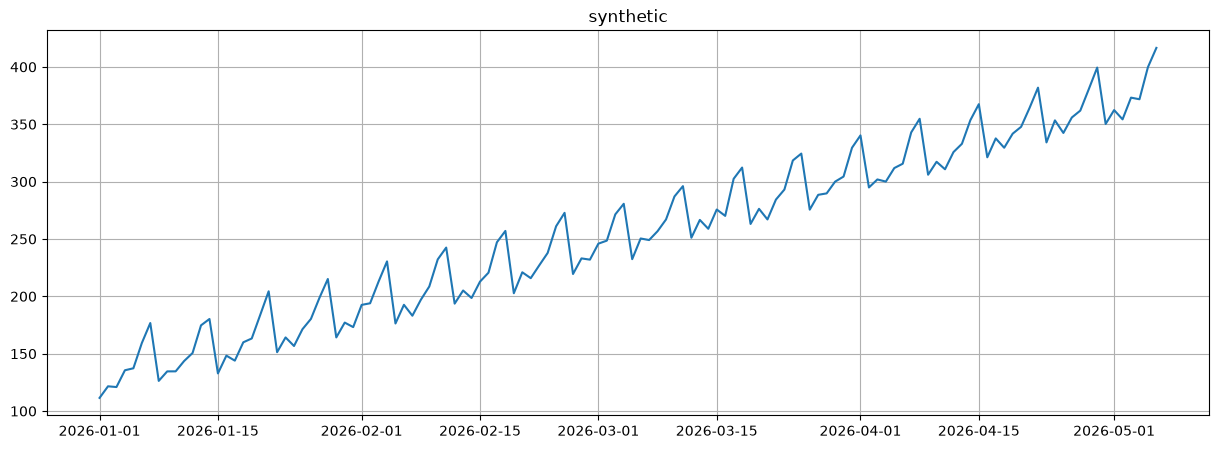

In [2]:
# Шаг 1.1. Генератор синтетики: линейный тренд + недельная сезонность + шум
DAY_OF_WEEK_PATTERN = np.array([10, 20, 15, 25, 30, 50, 60], dtype=float)


def make_trend_series(
    slope: float = 2,           # наклон тренда, заказов в день; 0 — ряд без тренда
    periods: int = 126,         # длина ряда: 18 недель
    start_level: float = 100,
    noise_sd: float = 3,
    seed: int = 42,
) -> TSDataset:
    rng = np.random.RandomState(seed)
    t = np.arange(periods)

    trend = start_level + slope * t
    seasonal = np.tile(DAY_OF_WEEK_PATTERN, periods // 7 + 1)[:periods]
    noise = rng.normal(0, noise_sd, periods)

    df = pd.DataFrame({
        "timestamp": pd.date_range("2026-01-01", periods=periods, freq="D"),
        "segment": "synthetic",
        "target": trend + seasonal + noise,
    })
    return TSDataset(df=df, freq="D")


ts = make_trend_series()  # тренд +2 в день
ts.plot(figsize=(15, 5));

#### Выводы

### Шаг 1.2. CatBoost против Prophet

Раздели на train / test (последние `HORIZON` дней). Обучи два конвейера:
- `Pipeline(CatBoostPerSegmentModel(random_seed=RANDOM_SEED), transforms=[LagTransform(in_column="target", lags=[14, 21, 28], out_column="lag")], horizon=HORIZON)`;
- `Pipeline(ProphetModel(), transforms=[], horizon=HORIZON)`.

Нарисуй оба прогноза на одном графике и посчитай SMAPE.

- Сравни максимум прогноза CatBoost с максимумом target в train и в test. Что видно?
- Почему так получилось? Вспомни раздел 1.1: что хранится в листьях дерева?

In [3]:
train_ts, test_ts = ts.train_test_split(test_size=HORIZON)

In [4]:
catboost_pipeline = Pipeline(
    CatBoostPerSegmentModel(random_seed=RANDOM_SEED),
    transforms=[
        LagTransform(in_column="target", lags=[14,21,28], out_column="lag")
    ],
    horizon=HORIZON
)

In [5]:
prophet_pipeline = Pipeline(
    ProphetModel(),
    transforms=[],
    horizon=HORIZON
)

In [6]:
forecasts = {}
for name, pipeline in {"catboost": catboost_pipeline, "prophet": prophet_pipeline}.items():
    pipeline.fit(train_ts)                 # трансформы применяются внутри, к копии
    forecasts[name] = pipeline.forecast()  # прогноз на HORIZON дней после train

errors = pd.Series({
    name: SMAPE()(y_true=test_ts, y_pred=forecast)["synthetic"]
    for name, forecast in forecasts.items()
}, name="smape").round(2)

catboost    2.10
prophet     0.84
Name: smape, dtype: float64


train_max                381.9
test_max                 416.6
catboost_forecast_max    381.3
prophet_forecast_max     409.7
dtype: float64

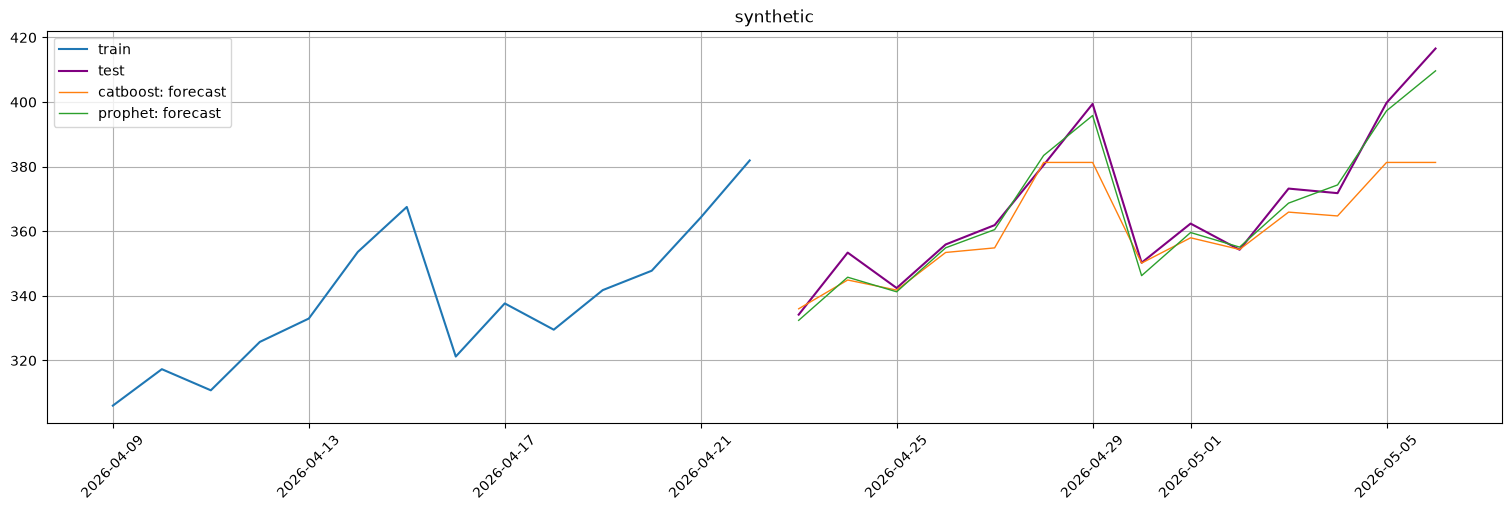

In [7]:
print(errors)

plot_forecast(forecast_ts=forecasts, test_ts=test_ts, train_ts=train_ts, n_train_samples=14, figsize=(15, 5))

pd.Series({
    "train_max": train_ts[:, "synthetic", "target"].max(),
    "test_max": test_ts[:, "synthetic", "target"].max(),
    **{f"{name}_forecast_max": forecast[:, "synthetic", "target"].max() for name, forecast in forecasts.items()},
}).round(1)

In [8]:
train_y = train_ts[:, "synthetic", "target"]
test_y = test_ts[:, "synthetic", "target"]
catboost_y = forecasts["catboost"][:, "synthetic", "target"]
prophet_y = forecasts["prophet"][:, "synthetic", "target"]
print(
    f"train_y.max(): {train_y.max()}\n",
    f"test_y.max(): {test_y.max()}\n",
    f"catboost_y.max(): {catboost_y.max()}\n",
    f"prophet_y.max(): {prophet_y.max()}\n"

)

compare_df = pd.DataFrame({
    "fact": test_y,
    "catboost": catboost_y,
    "prophet": prophet_y,
})
compare_df["catboost_error"] = compare_df["catboost"] - compare_df["fact"]
compare_df["prophet_error"] = compare_df["prophet"] - compare_df["fact"]
compare_df = compare_df[["fact", "catboost", "catboost_error", "prophet", "prophet_error"]]
compare_df.round(1)



train_y.max(): 381.92045837365237
 test_y.max(): 416.5713668774299
 catboost_y.max(): 381.30490726185076
 prophet_y.max(): 409.65734237566846



,fact,catboost,catboost_error,prophet,prophet_error
timestamp,,,,,
2026-04-23,334.2,336.0,1.8,332.4,-1.8
2026-04-24,353.4,344.9,-8.5,345.8,-7.6
2026-04-25,342.4,341.8,-0.6,341.3,-1.2
2026-04-26,355.9,353.4,-2.5,354.9,-1.0
2026-04-27,361.9,354.9,-7.0,360.5,-1.4
2026-04-28,380.5,381.3,0.8,383.5,3.0
2026-04-29,399.4,381.3,-18.1,395.8,-3.6
2026-04-30,350.3,350.1,-0.1,346.3,-4.0
2026-05-01,362.4,358.0,-4.4,359.6,-2.8


#### Выводы

- **Прогноз CatBoost упирается в потолок train.** Максимум прогноза 381.4 — почти ровно максимум train (381.9), хотя в тесте ряд дорастает до 416.6. Prophet за потолок выходит (409.7): он продолжает прямую тренда.
- **Потолок — это не один день, а плато.** В 4 из 14 дней CatBoost выдаёт одно и то же число 381.4. Это вторники и среды, самые сильные дни недели (+50 и +60 к тренду). В первый вторник (04-28) факт 380.5 ещё ниже потолка, и ошибка всего 0.9. В остальные три дня факт выше всего, что модель видела в train, и ошибка растёт вместе с трендом: −18.0 в первую среду (04-29), −18.3 и −35.1 во второй вторник и среду (05-05, 05-06). В остальные дни факт лежит внутри диапазона train, и CatBoost ошибается не сильнее Prophet (в пределах ±9).
- **SMAPE 2.12 против 0.84 — в 2.5 раза хуже,** и почти весь проигрыш дают эти 4 дня. На более длинном горизонте за потолок уйдут все дни недели, и прогноз превратится в почти постоянную линию.

**Почему так.** Дерево делит строки train по условиям вида `lag_14 > 352`, а в каждом листе хранит среднее target (точнее, остатков) обучающих строк, попавших в этот лист. Прогноз — сумма листьев всех деревьев, поэтому он не может уйти дальше значений, которые модель видела в train. Когда лаги в будущем больше всех лагов train, каждое дерево отправляет строку в свой «самый правый» лист — тот же, куда попадали максимальные строки train. Отсюда одинаковые 381.4: для модели все эти дни — «как самый большой день, что я видела». Связь «лаг вырос на 30 → target вырос на 30» модель не учит, она учит только «большой лаг → большой target из истории». Prophet же — формула $g(t) + s(t)$ с прямой тренда, и прямая продолжается за пределы истории сама.

### Шаг 1.3. Прогнозируем приращения

Добавь в начало списка трансформов `DifferencingTransform(in_column="target", period=..., inplace=True)` и повтори CatBoost с `period=1` и с `period=7`. Лаги оставь те же.

- Вышел ли прогноз за потолок train? Как изменился SMAPE относительно шага 1.2 и относительно Prophet?
- Какой `period` сработал лучше и почему? Подумай, что остаётся в приращениях $y_t - y_{t-1}$ и в $y_t - y_{t-7}$ на ряде «тренд + недельный паттерн».

In [9]:
# CatBoost на приращениях: DifferencingTransform первым — дальше лаги считаются уже от приращений,
# а при прогнозе Pipeline сам собирает уровень обратно (inverse_transform)
def make_diff_pipeline(period: int) -> Pipeline:
    return Pipeline(
        CatBoostPerSegmentModel(random_seed=RANDOM_SEED),
        transforms=[
            DifferencingTransform(in_column="target", period=period, inplace=True),
            LagTransform(in_column="target", lags=[14, 21, 28], out_column="lag"),
        ],
        horizon=HORIZON,
    )


# Прогнозы из шага 1.2 (catboost, prophet) + два новых варианта
for period in [1, 7]:
    pipeline = make_diff_pipeline(period)
    pipeline.fit(train_ts)
    forecasts[f"catboost_diff_{period}"] = pipeline.forecast()

errors = pd.Series({
    name: SMAPE()(y_true=test_ts, y_pred=forecast)["synthetic"]
    for name, forecast in forecasts.items()
}, name="smape").round(2)
print(errors)

catboost           2.10
prophet            0.84
catboost_diff_1    1.70
catboost_diff_7    1.01
Name: smape, dtype: float64


train_max                       381.9
test_max                        416.6
catboost_forecast_max           381.3
prophet_forecast_max            409.7
catboost_diff_1_forecast_max    424.1
catboost_diff_7_forecast_max    408.6
dtype: float64

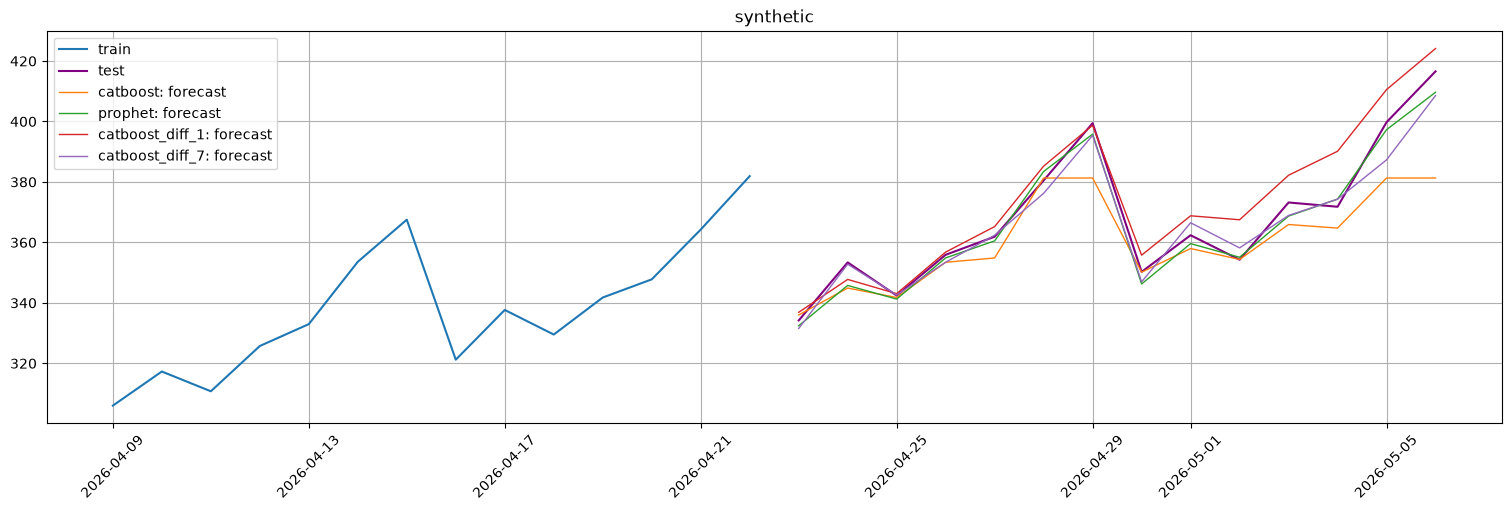

In [10]:
plot_forecast(forecast_ts=forecasts, test_ts=test_ts, train_ts=train_ts, n_train_samples=14, figsize=(15, 5))

# Вышел ли прогноз за потолок train
pd.Series({
    "train_max": train_ts[:, "synthetic", "target"].max(),
    "test_max": test_ts[:, "synthetic", "target"].max(),
    **{f"{name}_forecast_max": forecast[:, "synthetic", "target"].max() for name, forecast in forecasts.items()},
}).round(1)

In [11]:
# Ошибка по дням теста: факт и прогноз − факт для каждой модели
compare_diff_df = pd.DataFrame({"fact": test_ts[:, "synthetic", "target"]})
for name, forecast in forecasts.items():
    compare_diff_df[f"{name}_error"] = forecast[:, "synthetic", "target"] - compare_diff_df["fact"]
compare_diff_df["day_of_week"] = compare_diff_df.index.day_name()
compare_diff_df = compare_diff_df[["day_of_week", "fact", "prophet_error", "catboost_error", "catboost_diff_1_error", "catboost_diff_7_error"]]
compare_diff_df.round(1)

,day_of_week,fact,prophet_error,catboost_error,catboost_diff_1_error,catboost_diff_7_error
timestamp,,,,,,
2026-04-23,Thursday,334.2,-1.8,1.8,2.7,-2.7
2026-04-24,Friday,353.4,-7.6,-8.5,-5.6,-0.6
2026-04-25,Saturday,342.4,-1.2,-0.6,0.6,0.2
2026-04-26,Sunday,355.9,-1.0,-2.5,0.9,-2.5
2026-04-27,Monday,361.9,-1.4,-7.0,3.3,0.5
2026-04-28,Tuesday,380.5,3.0,0.8,4.7,-4.3
2026-04-29,Wednesday,399.4,-3.6,-18.1,-0.7,-4.0
2026-04-30,Thursday,350.3,-4.0,-0.1,5.5,-3.3
2026-05-01,Friday,362.4,-2.8,-4.4,6.4,4.1


,diff_1,diff_7
count,111.0,105.0
mean,2.4,13.9
std,22.4,3.8
min,-54.3,3.1
25%,-1.2,11.4
50%,10.2,14.1
75%,16.1,16.0
max,32.3,24.1


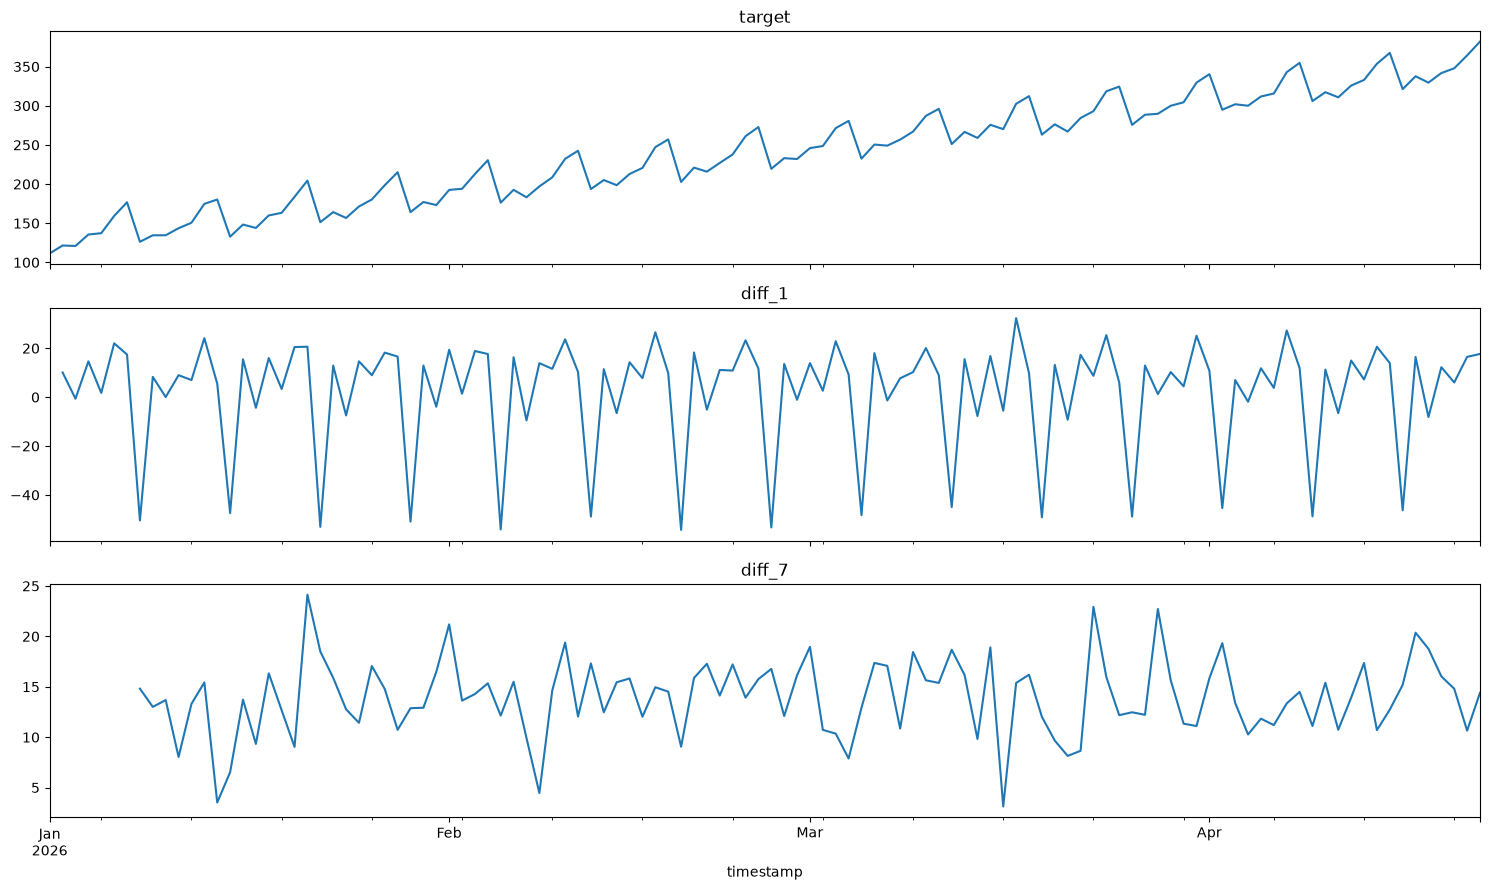

In [12]:
# Что остаётся в приращениях: на train видно, на чём модель учится в каждом варианте
increments_df = pd.DataFrame({
    "target": train_ts[:, "synthetic", "target"],
    "diff_1": train_ts[:, "synthetic", "target"].diff(1),
    "diff_7": train_ts[:, "synthetic", "target"].diff(7),
})

fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
for ax, column in zip(axes, increments_df.columns):
    increments_df[column].plot(ax=ax, title=column)
plt.tight_layout()

increments_df[["diff_1", "diff_7"]].describe().round(1)

#### Выводы

**Что поменялось.** Без `DifferencingTransform` CatBoost отвечал на вопрос «сколько будет заказов во вторник». С ним он отвечает на вопрос «на сколько этот вторник больше прошлого вторника» (`period=7`) или «на сколько сегодня больше, чем вчера» (`period=1`). Это и есть приращение. Само число заказов `Pipeline` собирает потом сам, простым сложением: **прогноз = значение неделю (или день) назад + прогноз приращения**.

**Потолка больше нет.** Максимум прогноза у `diff_7` — 408.3, у `diff_1` — 427.9, оба выше потолка train (381.9). Модель по-прежнему прогнозирует только числа из знакомого диапазона, но теперь это приращения: «+14 за неделю» модель в train видела много раз. Рост за потолок даёт сложение: прошлый вторник + 14.

**Почему `diff_7` лучше всех CatBoost (SMAPE 0.94 против 1.95 у `diff_1` и 2.12 без приращений).** В нашем ряде тренд +2 в день и недельный узор. Вторник минус прошлый вторник = 7 дней × 2 = **14**: узор вычитается сам из себя и исчезает, тренд превращается в одно постоянное число. Так и вышло: `diff_7` в train в среднем 13.9 при разбросе всего 3.8. Модели нужно выучить, по сути, одно число. Тренд и недельная форма приходят в прогноз из факта прошлой недели.

**Почему `diff_1` хуже.** Сегодня минус вчера убирает тренд (остаётся +2), но не убирает узор: «среда − вторник» и «четверг − среда» совсем разные. Поэтому `diff_1` скачет от −54 до +32, и модели приходится учить всю недельную форму. К тому же уровень собирается цепочкой из 14 дневных шагов, и каждая ошибка шага остаётся в прогнозе до конца. Видно по ошибкам: в первую неделю теста в среднем 2.6 по модулю, во вторую — уже 12.1, и почти все ошибки в одну сторону (выше факта).

**Почему вторник 05-05 у `diff_7` всё равно −12.7.** Прогноз на день — это «тот же день неделю назад + приращение». Для первой недели теста «неделя назад» — это факт из train. А для второй недели — уже наш собственный прогноз первой недели: факта там ещё нет. Цепочка такая: 05-05 = прогноз 04-28 + приращение = факт 04-21 + приращение + приращение.
- В последний вторник train (04-21) случайно было мало заказов — примерно на 6 меньше «нормы». Этот провал скопировался в оба тестовых вторника.
- Оба раза модель дала приращение чуть меньше 14 (около 11 и 10), и недобор сложился.

Это не рекурсия внутри модели: CatBoost все 14 приращений прогнозирует сразу, по известным лагам. Рекурсия возникает при сборке уровня обратно. Поэтому у `diff_7` ошибки во вторую неделю больше, чем в первую: в среднем 5.3 по модулю против 1.9. У Prophet, где такой цепочки нет, ошибка от недели к неделе почти не растёт: 2.8 и 3.4.

**Итог.** CatBoost не умеет продолжать тренд, но если дать ему ряд, где тренда нет, — приращения, — то справляется почти как Prophet (0.94 против 0.84). Лучше всего работает `period`, равный сезонности ряда: тогда одним вычитанием убираются и тренд, и сезонность.

### Шаг 1.4. Ряд без тренда

Сгенерируй тот же ряд с `slope=0` и повтори CatBoost (без дифференцирования) и Prophet.

- Насколько теперь отличаются модели?
- Сформулируй, на каких рядах CatBoost без дополнительных трансформов безопасен, а на каких нет.

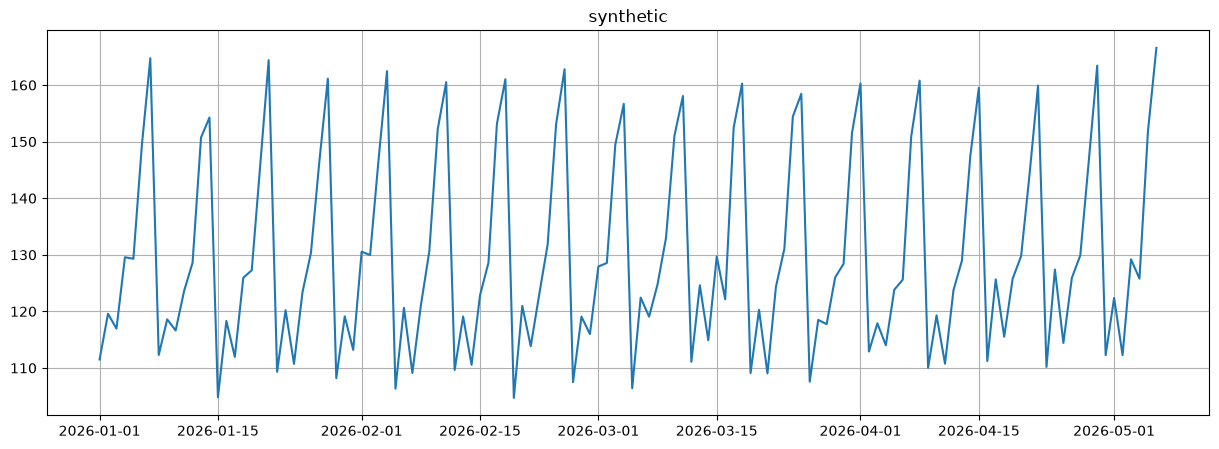

In [13]:
# Тот же ряд, но без тренда: только недельный узор + шум.
ts_flat = make_trend_series(slope=0)
ts_flat.plot(figsize=(15,5))

In [14]:
train_flat_ts, test_flat_ts = ts_flat.train_test_split(test_size=HORIZON)

flat_pipelines = {
    "catboost": Pipeline(
        CatBoostPerSegmentModel(random_seed=RANDOM_SEED),
        transforms=[LagTransform(in_column="target", lags=[14, 21, 28], out_column="lag")],
        horizon=HORIZON,
    ),
    "prophet": Pipeline(ProphetModel(), transforms=[], horizon=HORIZON),
    "catboost_diff_7": make_diff_pipeline(7),  # лучший вариант из шага 1.3 — нужен ли он без тренда?
}

forecasts_flat = {}
for name, pipeline in flat_pipelines.items():
    pipeline.fit(train_flat_ts)
    forecasts_flat[name] = pipeline.forecast()

errors_flat = pd.Series({
    name: SMAPE()(y_true=test_flat_ts, y_pred=forecast)["synthetic"]
    for name, forecast in forecasts_flat.items()
}, name="smape").round(2)
print(errors_flat)

catboost           2.47
prophet            2.26
catboost_diff_7    2.81
Name: smape, dtype: float64


train_max                       164.7
test_max                        166.6
catboost_forecast_max           160.0
prophet_forecast_max            160.0
catboost_diff_7_forecast_max    159.4
dtype: float64

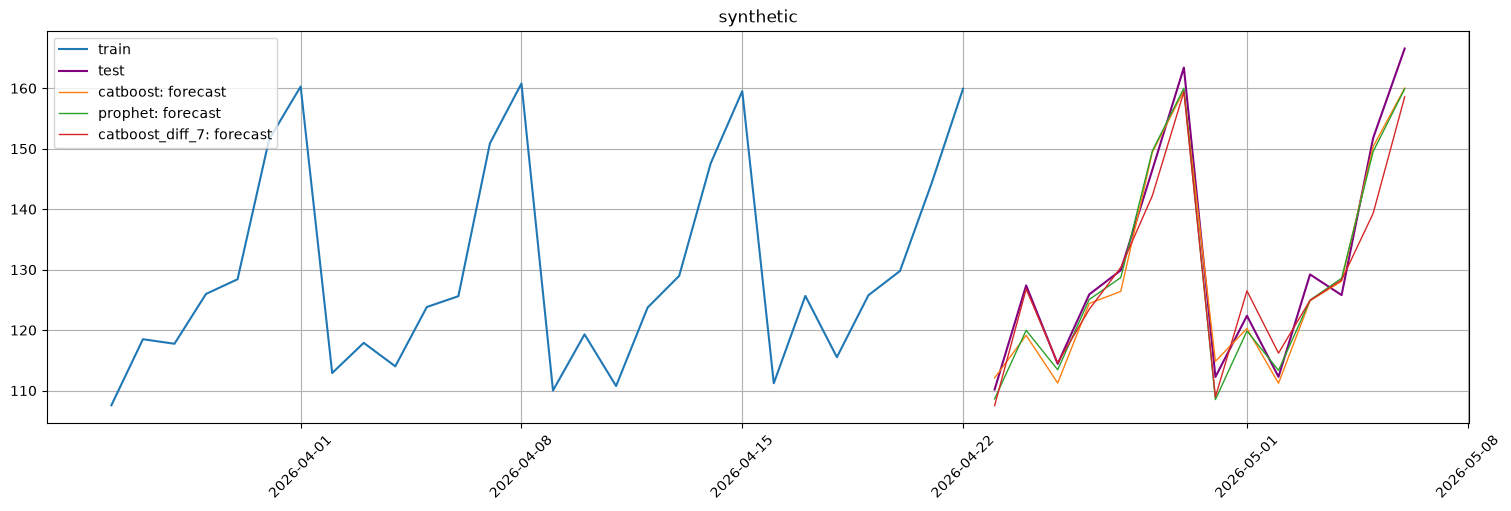

In [15]:
plot_forecast(forecast_ts=forecasts_flat, test_ts=test_flat_ts, train_ts=train_flat_ts, n_train_samples=28, figsize=(15, 5))

pd.Series({
    "train_max": train_flat_ts[:, "synthetic", "target"].max(),
    "test_max": test_flat_ts[:, "synthetic", "target"].max(),
    **{f"{name}_forecast_max": forecast[:, "synthetic", "target"].max() for name, forecast in forecasts_flat.items()},
}).round(1)

In [16]:
# Ошибка по дням теста: прогноз − факт
compare_flat_df = pd.DataFrame({
    "day_of_week": test_flat_ts.timestamps.day_name(),
    "fact": test_flat_ts[:, "synthetic", "target"],
}, index=test_flat_ts.timestamps)
for name, forecast in forecasts_flat.items():
    compare_flat_df[f"{name}_error"] = forecast[:, "synthetic", "target"] - compare_flat_df["fact"]

compare_flat_df.round(1)

,day_of_week,fact,catboost_error,prophet_error,catboost_diff_7_error
timestamp,,,,,
2026-04-23,Thursday,110.2,1.9,-1.6,-2.7
2026-04-24,Friday,127.4,-8.3,-7.4,-0.6
2026-04-25,Saturday,114.4,-3.2,-1.0,0.2
2026-04-26,Sunday,125.9,-1.5,-0.8,-2.5
2026-04-27,Monday,129.9,-3.5,-1.2,0.5
2026-04-28,Tuesday,146.5,2.9,3.1,-4.3
2026-04-29,Wednesday,163.4,-3.8,-3.4,-4.0
2026-04-30,Thursday,112.3,2.6,-3.7,-3.3
2026-05-01,Friday,122.4,-2.1,-2.5,4.1


#### Выводы

| модель | SMAPE с трендом (шаг 1.2–1.3) | SMAPE без тренда |
|---|---|---|
| `catboost` | 2.12 | **2.35** |
| `prophet` | 0.84 | **2.26** |
| `catboost_diff_7` | 0.94 | **2.60** |

**Без тренда CatBoost и Prophet ошибаются почти одинаково — и почти идеально.**
- Ошибки совпадают день в день: самые большие у обоих 04-24 (−8.1 и −7.4) и 05-06 (−6.4 и −6.7). Это не промах моделей, а шум: в эти дни факт случайно выше нормы (узора) на +7.4 и +6.6. Такое не предскажет никто.
- Проверка: модель, которая знает настоящий узор **точно**, получила бы на этом тесте SMAPE 2.15. У CatBoost 2.35, у Prophet 2.26 — обе почти упёрлись в этот предел. Всё, что можно выучить из ряда, они выучили.
- Потолок CatBoost здесь не мешает: тест лежит внутри диапазона train (кроме выброса 05-06 = 166.6, но его не угадал и Prophet: оба дают ~160).
- Почему SMAPE без тренда выше, чем у Prophet с трендом (2.26 против 0.84)? Шум тот же (±3 заказа), а уровень ряда в 3 раза ниже (~130 против ~360). SMAPE — ошибка в процентах, поэтому та же ошибка в заказах даёт больший процент.

**Дифференцирование без тренда — лишнее.**
- `catboost_diff_7` здесь худший (2.60), и его ошибки **до десятых совпадают с шагом 1.3**: −1.3, −0.4, …, −12.7, −8.3. Без тренда приращения за неделю те же, только меньше ровно на 14, поэтому модель выучила то же самое.
- Значит, и слабое место то же: прогноз = «тот же день неделю назад + приращение». Опора — один конкретный прошлый день со своим шумом, а во вторую неделю — собственный прогноз. Отсюда снова −12.7 во вторник 05-05, хотя CatBoost и Prophet в этот день почти не ошиблись (0.1 и −2.2).
- Модели без дифференцирования опираются на несколько недель сразу (лаги 14, 21, 28 у CatBoost, вся история у Prophet), и шум одного дня у них усредняется.

**Итог: когда CatBoost безопасен.**
- **Безопасен** — когда будущие значения лежат в том же диапазоне, что train: ряд колеблется вокруг постоянного уровня. Тогда CatBoost на лагах не уступает Prophet.
- **Опасен** — когда ряд уходит за пределы train: тренд, рост, сдвиг уровня вверх или вниз. Прогноз упрётся в потолок (шаг 1.2).
- **`DifferencingTransform` — лекарство от тренда, а не бесплатное улучшение.** Есть тренд — помогает сильно (шаг 1.3). Нет тренда — делает прогноз чуть хуже. Поэтому сначала смотрим на ряд, потом решаем.

## Задание 2. Какие признаки модель видит на самом деле

Разбираем трансформы из раздела 1.4 на ряде без тренда из шага 1.4: что лежит в таблице признаков на train и в будущем, что из этого попадает в модель и что ломается, если нарушить правило «лаг ≥ горизонта».

### Шаг 2.1. Таблица признаков: train и будущее

Раздели ряд на train / test и примени к train через `fit_transform` четыре трансформа:
- `LagTransform(in_column="target", lags=[1, 7, 14], out_column="lag")`;
- `MeanTransform(in_column="target", window=7, out_column="mean_target_7")` — как в пособии;
- `MeanTransform(in_column="lag_14", window=7, out_column="mean_lag14_7")` — по лагу;
- `DateFlagsTransform(day_number_in_week=True, day_number_in_month=False, is_weekend=False, out_column="flag")`.

Посмотри первые ~20 строк train и таблицу будущего: `train_ts.make_future(future_steps=HORIZON, transforms=...)`. Выведи `train_ts.regressors`.

- В каких колонках будущего есть `NaN` или нули и с какого дня?
- Какие колонки ETNA считает регрессорами, а какие нет?

In [17]:
# Признаки строим на копии train ряда без тренда из шага 1.4 — сам train_flat_ts не трогаем
def make_feature_transforms() -> list:
    """Четыре трансформа шага 2.1. Функция создаёт их ЗАНОВО — пригодится в шаге 2.2."""
    return [
        LagTransform(in_column="target", lags=[1, 7, 14], out_column="lag"),
        MeanTransform(in_column="target", window=7, out_column="mean_target_7"),   # как в пособии: по target
        MeanTransform(in_column="lag_14", window=7, out_column="mean_lag14_7"),    # по лагу: среднее y[t-14] … y[t-20]
        DateFlagsTransform(day_number_in_week=True, day_number_in_month=False, is_weekend=False, out_column="flag"),
    ]


feature_transforms = make_feature_transforms()
features_train_ts = deepcopy(train_flat_ts)
features_train_ts.fit_transform(feature_transforms)

features_train_df = features_train_ts.to_pandas(flatten=True).drop(columns="segment").set_index("timestamp")
features_train_df.head(22).round(1)

,target,flag_day_number_in_week,lag_1,lag_14,lag_7,mean_lag14_7,mean_target_7
timestamp,,,,,,,
2026-01-01,111.5,3,NaN,NaN,NaN,0.0,111.5
2026-01-02,119.6,4,111.5,NaN,NaN,0.0,115.5
2026-01-03,116.9,5,119.6,NaN,NaN,0.0,116.0
2026-01-04,129.6,6,116.9,NaN,NaN,0.0,119.4
2026-01-05,129.3,0,129.6,NaN,NaN,0.0,121.4
2026-01-06,149.3,1,129.3,NaN,NaN,0.0,126.0
2026-01-07,164.7,2,149.3,NaN,NaN,0.0,131.6
2026-01-08,112.3,3,164.7,NaN,111.5,0.0,131.7
2026-01-09,118.6,4,112.3,NaN,119.6,0.0,131.5


In [18]:
# Будущее: те же трансформы, target пустой — модель увидит ровно эти признаки
features_future_df = (
    features_train_ts.make_future(future_steps=HORIZON, transforms=feature_transforms)
    .to_pandas(flatten=True)
    .drop(columns="segment")
    .set_index("timestamp")
)

features_future_df.round(1)

,target,flag_day_number_in_week,lag_1,lag_14,lag_7,mean_lag14_7,mean_target_7
timestamp,,,,,,,
2026-04-23,NaN,3,159.9,110.0,111.2,129.0,133.5
2026-04-24,NaN,4,NaN,119.3,125.7,129.2,135.0
2026-04-25,NaN,5,NaN,110.8,115.5,128.7,139.9
2026-04-26,NaN,6,NaN,123.7,125.8,128.7,144.6
2026-04-27,NaN,0,NaN,129.0,129.8,129.2,152.1
2026-04-28,NaN,1,NaN,147.6,144.2,128.7,159.9
2026-04-29,NaN,2,NaN,159.5,159.9,128.6,0.0
2026-04-30,NaN,3,NaN,111.2,NaN,128.7,0.0
2026-05-01,NaN,4,NaN,125.7,NaN,129.6,0.0


In [19]:
# Сводка по колонкам: регрессор ли (известна ли в будущем) и сколько пропусков / нулей в train и в будущем
feature_columns = [column for column in features_future_df.columns if column != "target"]
features_summary_df = pd.DataFrame({
    "is_regressor": [column in features_train_ts.regressors for column in feature_columns],
    "train_nan": features_train_df[feature_columns].isna().sum(),
    "future_nan": features_future_df[feature_columns].isna().sum(),
    # нули считаем только в числовых колонках: у flag_day_number_in_week 0 — это понедельник
    "future_zero": (features_future_df[feature_columns].select_dtypes("number") == 0).sum(),
}, index=feature_columns)

print("regressors:", features_train_ts.regressors)
features_summary_df

regressors: ['lag_14', 'lag_1', 'mean_lag14_7', 'lag_7', 'flag_day_number_in_week']


,is_regressor,train_nan,future_nan,future_zero
flag_day_number_in_week,True,0,0,NaN
lag_1,True,1,13,0.0
lag_14,True,14,0,0.0
lag_7,True,7,7,0.0
mean_lag14_7,True,0,0,0.0
mean_target_7,False,0,0,8.0


#### Выводы

**Правило одно: лаг $k$ — это «значение $k$ дней назад». Дыра появляется там, где на $k$ дней назад данных нет.** Дыры бывают в двух местах:

| признак | дыра в начале train | дыра в будущем (14 дней теста) |
|---|---|---|
| `lag_1` | 1 строка | **13 из 14 дней** — известен только 1-й день |
| `lag_7` | 7 строк | **7 из 14 дней** — известны дни 1–7 |
| `lag_14` | 14 строк | **нет** — известны все 14 дней |
| `mean_lag14_7` | нет `NaN`, но 14 строк **нулей** | нет |
| `flag_day_number_in_week` | нет | нет — день недели известен всегда |
| `mean_target_7` | нет | **дни 7–14 — нули**, дни 1–6 — «съезжающее» среднее |

**Train: дыра — в начале истории.** У первого дня ряда нет «вчера», у первой недели нет «неделю назад». Строки с `NaN` модель выбросит перед обучением (раздел 1.3): с лагами до 14 обучение начнётся только с 15-й строки (2026-01-15). Чем длиннее лаг, тем больше истории теряем.

**Будущее: дыра — в конце горизонта.** Прогноз делаем 2026-04-22 (последний день train). Для 1-го дня теста «вчера» — это 04-22, факт есть. Для 2-го дня «вчера» — это 1-й день теста, а его факта ещё нет. Поэтому:
- `lag_1` известен только на 1 день вперёд, `lag_7` — на 7, `lag_14` — на все 14;
- **лаг без дыр в будущем — только лаг ≥ горизонта.** Отсюда правило «порядок лага не меньше `HORIZON`».

**Два тихих подвоха — не `NaN`, а ноль.**
- `mean_lag14_7` в первых 14 строках train — `0.0`, а не `NaN`: так работает `fillna=0` у `MeanTransform`. Это не «ноль заказов», а «посчитать нечем». Здесь не страшно — те же строки всё равно выброшены из-за `NaN` в `lag_14`, — но если оставить только среднее без лага, модель будет учиться на фальшивых нулях. Плюс строки 15–20: окно заполнено не целиком (`min_periods=1`) — в 01-15 «среднее за 7 дней» на деле одно значение (111.5).
- `mean_target_7` в будущем: в первые 6 дней окно захватывает всё меньше дней train (в 6-й день — только последний, 159.9), а с 7-го дня внутри окна не остаётся ничего, и подставляется `0.0`. Модели ни ошибки, ни `NaN` — просто бессмысленные числа.

**Регрессоры.** ETNA считает регрессорами все колонки, кроме `mean_target_7`: лаги, день недели и среднее по `lag_14`. `mean_target_7` построено по `target`, а у `target` нет будущего — поэтому не регрессор. Что это значит для модели — в шаге 2.2.

**Итог.** Признак годится для прогноза на весь горизонт, только если он смотрит в прошлое не меньше, чем на `HORIZON` дней: `lag_14`, `mean_lag14_7`. Или если он известен заранее: день недели. Остальное либо дырявое в будущем (`lag_1`, `lag_7`), либо вообще не попадёт в модель (`mean_target_7`).

### Шаг 2.2. Что попало в модель

Обучи `CatBoostPerSegmentModel(random_seed=RANDOM_SEED)` на преобразованном train из шага 2.1 и выведи `model.get_model()["synthetic"].feature_names_`.

- Где `mean_target_7`? Почему его нет (раздел 1.3)?
- Сравни в train значение `mean_target_7` в строке $t$ с `target` той же строки и предыдущих 6 строк. Что было бы, если бы модель этот признак взяла?

In [20]:
# Обучаем CatBoost на таблице признаков из шага 2.1 и смотрим, какие колонки он реально взял
model_features = CatBoostPerSegmentModel(random_seed=RANDOM_SEED)
model_features.fit(features_train_ts)

used_features = model_features.get_model()["synthetic"].feature_names_
all_columns = [column for column in features_train_df.columns if column != "target"]

print("колонки в таблице:  ", all_columns)
print("признаки в модели:  ", used_features)
print("выброшены моделью:  ", sorted(set(all_columns) - set(used_features)))

колонки в таблице:   ['flag_day_number_in_week', 'lag_1', 'lag_14', 'lag_7', 'mean_lag14_7', 'mean_target_7']
признаки в модели:   ['lag_14', 'lag_1', 'mean_lag14_7', 'lag_7', 'flag_day_number_in_week']
выброшены моделью:   ['mean_target_7']


In [21]:
# Утечка: из чего состоит mean_target_7 в строке t? Считаем два варианта среднего по target вручную
leak_df = features_train_df[["target", "mean_target_7"]].copy()
leak_df["mean_with_today"] = leak_df["target"].rolling(7, min_periods=1).mean()              # дни t-6 … t
leak_df["mean_without_today"] = leak_df["target"].shift(1).rolling(7, min_periods=1).mean()  # дни t-7 … t-1
leak_df.iloc[7:15].round(1)

,target,mean_target_7,mean_with_today,mean_without_today
timestamp,,,,
2026-01-08,112.3,131.7,131.7,131.6
2026-01-09,118.6,131.5,131.5,131.7
2026-01-10,116.6,131.5,131.5,131.5
2026-01-11,123.6,130.6,130.6,131.5
2026-01-12,128.6,130.5,130.5,130.6
2026-01-13,150.7,130.7,130.7,130.5
2026-01-14,154.3,129.2,129.2,130.7
2026-01-15,104.8,128.2,128.2,129.2


In [22]:
# Что было бы, если бы модель взяла mean_target_7: обучаем CatBoost напрямую, мимо ETNA, на тех же колонках
from catboost import CatBoostRegressor

leak_columns = ["lag_14", "flag_day_number_in_week", "mean_target_7"]
clean_columns = ["lag_14", "flag_day_number_in_week", "mean_lag14_7"]

train_rows = features_train_df.dropna(subset=["lag_14"])  # как ETNA: строки без lag_14 выбрасываем
test_fact = test_flat_ts[:, "synthetic", "target"]

leak_rows = []
for name, columns in {"with_mean_target_7": leak_columns, "with_mean_lag14_7": clean_columns}.items():
    regressor = CatBoostRegressor(random_seed=RANDOM_SEED, logging_level="Silent", cat_features=["flag_day_number_in_week"])
    regressor.fit(train_rows[columns], train_rows["target"])
    train_pred = regressor.predict(train_rows[columns])
    test_pred = pd.Series(regressor.predict(features_future_df[columns]), index=features_future_df.index)
    leak_rows.append({
        "features": name,
        "train_mae": (train_pred - train_rows["target"]).abs().mean(),   # ошибка на тех строках, где училась
        "test_mae": (test_pred - test_fact).abs().mean(),                # ошибка на 14 днях теста
        "test_mae_days_1_6": (test_pred - test_fact).abs().iloc[:6].mean(),
        "test_mae_days_7_14": (test_pred - test_fact).abs().iloc[6:].mean(),
        "importance_of_mean": regressor.get_feature_importance(prettified=True).set_index("Feature Id").loc[columns[-1], "Importances"],
    })

pd.DataFrame(leak_rows).set_index("features").round(2)

,train_mae,test_mae,test_mae_days_1_6,test_mae_days_7_14,importance_of_mean
features,,,,,
with_mean_target_7,1.03,3.91,1.96,5.38,7.05
with_mean_lag14_7,1.22,3.71,3.64,3.77,4.94


#### Выводы

**В модель попали 5 признаков из 6.** `lag_1`, `lag_7`, `lag_14`, `mean_lag14_7`, день недели — да. `mean_target_7` — нет: ETNA выбросила его молча, без ошибки и без предупреждения. Причина из шага 2.1: это не регрессор (у `target` нет будущего), а CatBoost в ETNA берёт **только регрессоры**. Обрати внимание: `lag_1` и `lag_7` в модель попали, хотя в будущем они дырявые, — ETNA проверяет «есть ли будущее у колонки», а не «хватит ли его на весь горизонт».

**`mean_target_7` подглядывает в ответ.** Ручной пересчёт показывает, из чего он сделан:

| | окно | совпадает с `mean_target_7`? |
|---|---|---|
| `mean_with_today` | дни $t-6 \ldots t$ — **включая сегодня** | да, до десятых |
| `mean_without_today` | дни $t-7 \ldots t-1$ | нет |

То есть в строке за 14 января признак содержит заказы за 14 января — то самое число, которое модель должна предсказать. Это **утечка**: в train ответ лежит внутри признака, а в будущем его там нет.

**Что было бы, если бы модель его взяла.** Обучили CatBoost в обход ETNA на двух наборах (лаг 14 + день недели + одно из средних):

| признак-среднее | ошибка на train | ошибка на тесте | дни 1–6 | дни 7–14 |
|---|---|---|---|---|
| `mean_target_7` (с утечкой) | **1.03** | 3.91 | 1.96 | **5.38** |
| `mean_lag14_7` (честный) | 1.22 | **3.71** | 3.64 | 3.77 |

- **На train утечка выглядит лучше** (1.03 против 1.22): модель «знает» кусочек ответа. Так утечка и обманывает — на обучении всё хорошо.
- **На тесте — хуже** (3.91 против 3.71). Особенно в днях 7–14 (5.38 против 3.77): там окно уже целиком в будущем, и признак превращается в `0.0` (шаг 2.1). Модель такого значения в train не видела и прогнозирует наугад.
- Дни 1–6 у утечки случайно лучше (1.96): признак там считается по всё более короткому окну из последних дней train, и на 6 точках это совпадение, а не закономерность.
- Здесь эффект умеренный: сегодняшний день — лишь 1/7 окна. Чем короче окно, тем сильнее утечка: при `window=1` признак просто **равен** target, на train ошибка была бы ~0, а на тесте признак с 1-го дня — ноль.

**Итог.**
- ETNA защищает от этой ошибки сама: признак по `target` в модель не попадёт. Но молча — поэтому стоит проверять `feature_names_`.
- Скользящие статистики строим **по лагу ≥ горизонта** (`mean_lag14_7`), а не по `target`. Тогда окно всегда в прошлом, без утечки и без нулей в будущем.
- От дырявых лагов (`lag_1`, `lag_7`) ETNA **не** защищает — это следующий шаг 2.3.

### Шаг 2.3. Лаг меньше горизонта

Через `Pipeline` сравни три набора лагов на одном и том же ряде:
- `lags=[14, 21, 28]` — все лаги ≥ горизонта;
- `lags=[1, 7, 14]` — короткие лаги, свежая информация;
- `lags=list(range(1, 14))` — только лаги меньше горизонта.

- Какой набор лучше по SMAPE? Ожидал ли ты такого результата, учитывая, что у наборов с короткими лагами в train больше свежей информации?
- Посмотри важности признаков: какой лаг модель считала главным на train и в какие дни теста он у неё вообще есть?
- Выдала ли ETNA ошибку или предупреждение? Что CatBoost делает с `NaN` в будущих строках (раздел 1.3)?

lags_14_21_28    2.47
lags_1_7_14      7.35
lags_1_to_13     7.04
Name: smape, dtype: float64


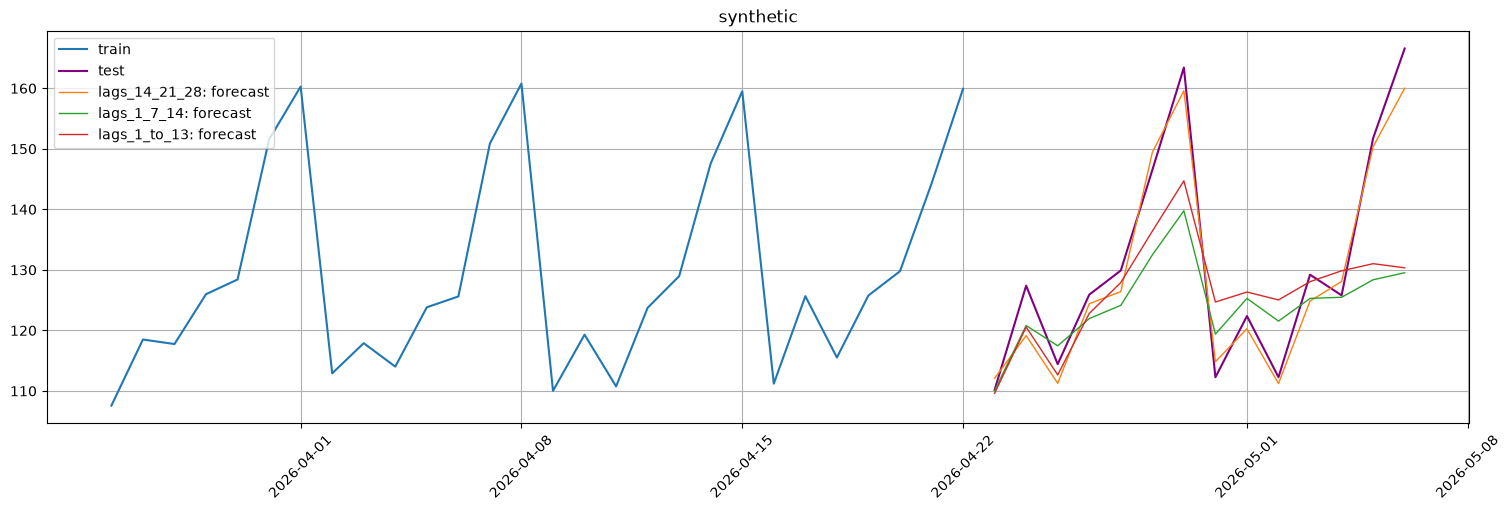

In [23]:
# Три набора лагов на ряде без тренда из шага 1.4: модель и всё остальное одинаковое, меняются только лаги
lag_sets = {
    "lags_14_21_28": [14, 21, 28],         # все лаги ≥ горизонта
    "lags_1_7_14": [1, 7, 14],             # свежая информация, но lag_1 и lag_7 дырявые в будущем
    "lags_1_to_13": list(range(1, 14)),    # только лаги меньше горизонта
}

lag_pipelines = {}
forecasts_lags = {}
for name, lags in lag_sets.items():
    lag_pipelines[name] = Pipeline(
        CatBoostPerSegmentModel(random_seed=RANDOM_SEED),
        transforms=[LagTransform(in_column="target", lags=lags, out_column="lag")],
        horizon=HORIZON,
    )
    lag_pipelines[name].fit(train_flat_ts)
    forecasts_lags[name] = lag_pipelines[name].forecast()

errors_lags = pd.Series({
    name: SMAPE()(y_true=test_flat_ts, y_pred=forecast)["synthetic"]
    for name, forecast in forecasts_lags.items()
}, name="smape").round(2)
print(errors_lags)

plot_forecast(forecast_ts=forecasts_lags, test_ts=test_flat_ts, train_ts=train_flat_ts, n_train_samples=28, figsize=(15, 5))

In [24]:
# Ошибка по дням теста + сколько признаков модели в этот день известны (не NaN)
features_known_df = pd.DataFrame(index=test_flat_ts.timestamps)
for name, lags in lag_sets.items():
    known_lags = pd.Series(range(1, HORIZON + 1), index=test_flat_ts.timestamps).apply(
        lambda day: sum(lag >= day for lag in lags)  # лаг k известен в день h теста, только если k ≥ h
    )
    features_known_df[f"{name}_known"] = known_lags.astype(str) + "/" + str(len(lags))

compare_lags_df = pd.DataFrame({
    "day": range(1, HORIZON + 1),
    "fact": test_flat_ts[:, "synthetic", "target"],
}, index=test_flat_ts.timestamps)
for name, forecast in forecasts_lags.items():
    compare_lags_df[f"{name}_error"] = forecast[:, "synthetic", "target"] - compare_lags_df["fact"]
compare_lags_df = compare_lags_df.join(features_known_df)

compare_lags_df.round(1)

,day,fact,lags_14_21_28_error,lags_1_7_14_error,lags_1_to_13_error,lags_14_21_28_known,lags_1_7_14_known,lags_1_to_13_known
timestamp,,,,,,,,
2026-04-23,1,110.2,1.9,-0.1,-0.6,3/3,3/3,13/13
2026-04-24,2,127.4,-8.3,-6.6,-6.8,3/3,2/3,12/13
2026-04-25,3,114.4,-3.2,3.0,-1.8,3/3,2/3,11/13
2026-04-26,4,125.9,-1.5,-4.0,-3.1,3/3,2/3,10/13
2026-04-27,5,129.9,-3.5,-5.8,-2.0,3/3,2/3,9/13
2026-04-28,6,146.5,2.9,-14.0,-10.1,3/3,2/3,8/13
2026-04-29,7,163.4,-3.8,-23.7,-18.7,3/3,2/3,7/13
2026-04-30,8,112.3,2.6,7.1,12.4,3/3,1/3,6/13
2026-05-01,9,122.4,-2.1,2.9,4.0,3/3,1/3,5/13


In [25]:
# Какой признак модель считала главным на train — и известен ли он ей в будущем (см. *_known в таблице выше)
importance_lags_df = pd.DataFrame({
    name: pipeline.model.get_model()["synthetic"].get_feature_importance(prettified=True).set_index("Feature Id")["Importances"]
    for name, pipeline in lag_pipelines.items()
})
importance_lags_df = importance_lags_df.sort_index(key=lambda index: index.str.removeprefix("lag_").astype(int))  # lag_1, lag_2, …
importance_lags_df.round(1)

,lags_14_21_28,lags_1_7_14,lags_1_to_13
Feature Id,,,
lag_1,NaN,16.4,2.9
lag_2,NaN,NaN,3.0
lag_3,NaN,NaN,2.8
lag_4,NaN,NaN,7.0
lag_5,NaN,NaN,4.5
lag_6,NaN,NaN,2.0
lag_7,NaN,40.1,55.7
lag_8,NaN,NaN,2.6
lag_9,NaN,NaN,1.2


#### Выводы

| набор лагов | SMAPE | главный признак на train (важность) | когда он есть в тесте |
|---|---|---|---|
| `14, 21, 28` | **2.35** | `lag_14` (39), `lag_28` (38) | все 14 дней |
| `1, 7, 14` | 7.59 | `lag_14` (46), `lag_7` (38) | `lag_7` — только дни 1–7 |
| `1 … 13` | 7.48 | `lag_7` (59) | только дни 1–7 |

**Короткие лаги — в 3 раза хуже.** И это при том, что «на бумаге» у них больше свежей информации.

**Почему: модель учили с признаками, а прогнозировать заставили без них.**
- На train у модели с короткими лагами все признаки есть всегда, и главный из них — `lag_7` (38 и 59 из 100): ряд недельный, «тот же день неделю назад» говорит о сегодняшнем дне больше всего.
- В тесте `lag_7` есть только первые 7 дней, `lag_1` — только 1-й день. Колонки `*_known` показывают, как признаки пропадают: у `1 … 13` к последнему дню не остаётся **ни одного** (0/13).
- Прогноз 05-06 у `1 … 13` построен вообще без признаков — и ошибка −37.9, самая большая в таблице.

**Как это видно по дням.**
- **Дни 1–5** — короткие лаги ошибаются примерно как длинные. Почти все признаки ещё на месте.
- **Пики (вторник и среда) — главные провалы:** −13.8 и −26.6 в первую неделю, −23.8 и −38.1 во вторую. Пустой признак CatBoost читает как «значение меньше любого из train» (раздел 1.3), то есть как «неделю назад был провал». Модель прогнозирует низко там, где на самом деле пик.
- **Спокойные дни во второй неделе — наоборот, перелёт** (четверг и суббота: от +7 до +15): без `lag_7` модель не может отличить, какой это день недели, и выдаёт «что-то среднее».
- У `14, 21, 28` ошибки ровные всю дорогу (от −8 до +3): все признаки на месте каждый день.

**Свежий `lag_1` тут вообще не помог.** Даже в 1-й день, когда он известен, выигрыша нет (−0.6 против 1.6 — в пределах шума). В синтетике шум каждого дня независимый: «вчера было больше нормы» ничего не говорит о завтра. На реальных данных вчерашний день может быть полезнее — но использовать его с прямой стратегией всё равно нельзя.

**ETNA и CatBoost не предупредили ни о чём.** Ни ошибки, ни предупреждения: `lag_1` — регрессор (шаг 2.2), а `NaN` CatBoost принимает молча. Модель тихо выдаёт плохой прогноз.

**Итог.**
- **Правило: порядок лага ≥ горизонта.** При `HORIZON = 14` — лаги от 14 и дальше. Проверка простая: у каждого признака в таблице будущего (шаг 2.1) не должно быть `NaN`.
- Хочешь использовать вчерашний день — нужен другой подход: `AutoRegressivePipeline` прогнозирует по одному дню и подставляет свои прогнозы в лаги (рекурсия, как у `SARIMAXModel`).

### Шаг 2.4. Важность признаков и SHAP-компоненты

Обучи конвейер с лагами `list(range(14, 29))` (все лаги с 14-го по 28-й).

1. Выведи важности `pipeline.model.get_model()["synthetic"].get_feature_importance(prettified=True)`.
2. Построй `plot_feature_relevance` с `ModelRelevanceTable()` и `RandomForestRegressor` (на `train_ts` после `fit_transform` с теми же лагами).
3. Получи прогноз с `return_components=True` и проверь, что компоненты в сумме дают прогноз.

- Какие лаги важнее всего и почему именно они (подумай про период паттерна)?
- Совпадают ли топы CatBoost и случайного леса?
- Чем компоненты CatBoost по смыслу отличаются от компонент `ProphetModel` (тренд + недельная волна)?

In [26]:
# Конвейер со всеми лагами с 14-го по 28-й: какие из них модель сочтёт важными?
importance_lags = list(range(14, 29))
importance_pipeline = Pipeline(
    CatBoostPerSegmentModel(random_seed=RANDOM_SEED),
    transforms=[LagTransform(in_column="target", lags=importance_lags, out_column="lag")],
    horizon=HORIZON,
)
importance_pipeline.fit(train_flat_ts)

# Важность в CatBoost (PredictionValuesChange): сколько в среднем меняется прогноз из-за признака, в сумме 100
catboost_importance = (
    importance_pipeline.model.get_model()["synthetic"]
    .get_feature_importance(prettified=True)
    .set_index("Feature Id")["Importances"]
)
catboost_importance.round(1)

Feature Id
lag_14    25.9
lag_21    24.9
lag_28    13.8
lag_26     4.5
lag_27     3.8
lag_22     3.7
lag_20     3.5
lag_19     3.3
lag_24     3.1
lag_17     3.0
lag_16     2.7
lag_18     2.6
lag_25     1.8
lag_23     1.7
lag_15     1.7
Name: Importances, dtype: float64

/Users/skv/projects-skv/study-etna/.venv/lib/python3.11/site-packages/etna/analysis/feature_relevance/relevance_table.py:33: UserWarning: Exogenous or target data contains None! It will be dropped for calculating relevance.
  warnings.warn("Exogenous or target data contains None! It will be dropped for calculating relevance.")


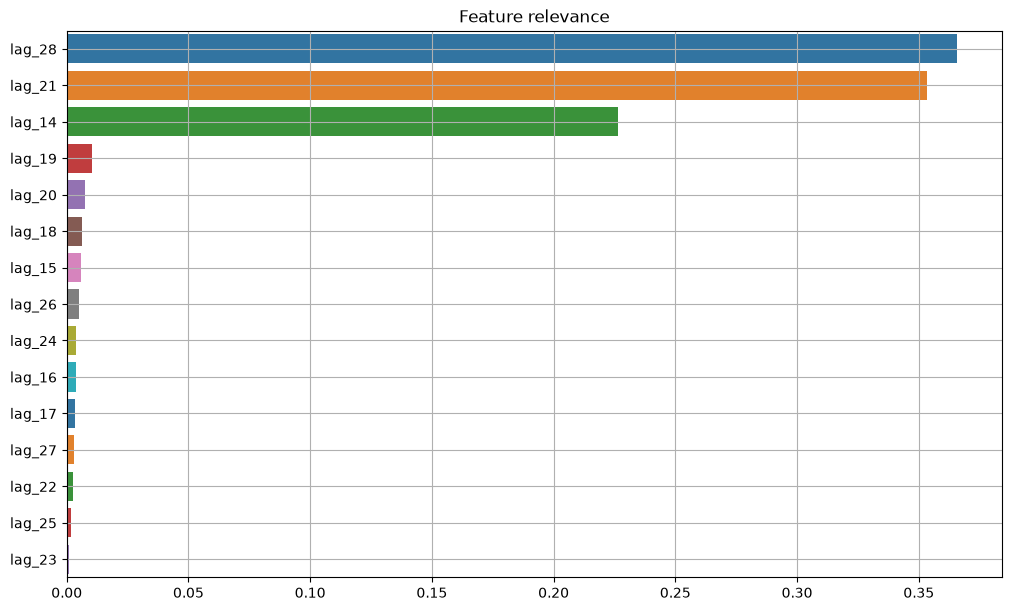

In [27]:
# Те же лаги — но важности по отдельной модели, случайному лесу (как в пособии)
importance_train_ts = deepcopy(train_flat_ts)
importance_transforms = [LagTransform(in_column="target", lags=importance_lags, out_column="lag")]
importance_train_ts.fit_transform(importance_transforms)

plot_feature_relevance(
    ts=importance_train_ts,
    relevance_table=ModelRelevanceTable(),
    normalized=True,  # в сумме 1
    relevance_params=dict(model=RandomForestRegressor(n_estimators=100, random_state=RANDOM_SEED)),
    figsize=(10, 6),
)

In [28]:
# Сравниваем топы: те же важности леса числами (ModelRelevanceTable сама выбрасывает строки с NaN)
importance_train_df = importance_train_ts.to_pandas(flatten=True).dropna()
lag_columns = [f"lag_{lag}" for lag in importance_lags]
forest = RandomForestRegressor(n_estimators=100, random_state=RANDOM_SEED).fit(importance_train_df[lag_columns], importance_train_df["target"])

importance_compare_df = pd.DataFrame({
    "lag_days_ago": importance_lags,
    "same_weekday": [lag % 7 == 0 for lag in importance_lags],  # лаг кратен 7 — тот же день недели
    "catboost": catboost_importance.reindex(lag_columns).values,
    "random_forest": forest.feature_importances_ * 100,         # тоже в сумме 100
}, index=lag_columns)
importance_compare_df["catboost_rank"] = importance_compare_df["catboost"].rank(ascending=False).astype(int)
importance_compare_df["random_forest_rank"] = importance_compare_df["random_forest"].rank(ascending=False).astype(int)
importance_compare_df.sort_values("catboost", ascending=False).round(1)

,lag_days_ago,same_weekday,catboost,random_forest,catboost_rank,random_forest_rank
lag_14,14,True,25.9,22.7,1,3
lag_21,21,True,24.9,35.3,2,2
lag_28,28,True,13.8,36.6,3,1
lag_26,26,False,4.5,0.5,4,8
lag_27,27,False,3.8,0.3,5,12
lag_22,22,False,3.7,0.3,6,13
lag_20,20,False,3.5,0.7,7,5
lag_19,19,False,3.3,1.0,8,4
lag_24,24,False,3.1,0.4,9,9
lag_17,17,False,3.0,0.3,10,11


In [29]:
# SHAP-компоненты: прогноз раскладывается на вклады признаков
forecast_components_ts = importance_pipeline.forecast(return_components=True)
components_df = forecast_components_ts.get_target_components()["synthetic"]
components_df.columns = components_df.columns.str.removeprefix("target_component_")

# Проверка: сумма вкладов = прогноз
forecast_y = forecast_components_ts[:, "synthetic", "target"]
print(f"максимальное расхождение суммы компонент и прогноза: {(forecast_y - components_df.sum(axis=1)).abs().max():.2e}")

# Подвох: ETNA делит базовое значение модели (средний прогноз) поровну между всеми признаками
# (etna/models/catboost.py, predict_components). Достаём базу из самого CatBoost, чтобы отделить её от вкладов
from catboost import Pool

future_features_df = importance_train_ts.make_future(future_steps=HORIZON, transforms=importance_transforms).to_pandas(flatten=True)
shap_values = importance_pipeline.model.get_model()["synthetic"].get_feature_importance(
    Pool(future_features_df[lag_columns]), type="ShapValues"
)
base_value = shap_values[0, -1]  # последний столбец — база, одинаковая для всех строк
pure_shap_df = components_df[lag_columns] - base_value / len(lag_columns)  # чистые вклады признаков

print(f"база модели: {base_value:.1f}, на каждый из {len(lag_columns)} лагов ETNA добавила по {base_value / len(lag_columns):.1f}")
components_df.iloc[:3].round(1)

максимальное расхождение суммы компонент и прогноза: 8.53e-14
база модели: 129.7, на каждый из 15 лагов ETNA добавила по 8.6


feature,lag_14,lag_15,lag_16,lag_17,lag_18,lag_19,lag_20,lag_21,lag_22,lag_23,lag_24,lag_25,lag_26,lag_27,lag_28
timestamp,,,,,,,,,,,,,,,
2026-04-23,4.1,7.9,8.2,8.1,7.9,8.5,7.7,4.9,8.1,8.3,7.8,8.4,8.4,7.7,4.2
2026-04-24,6.4,8.6,8.6,7.4,8.0,8.7,8.4,6.1,8.7,8.6,7.7,8.3,8.5,8.0,6.1
2026-04-25,5.7,8.3,8.4,6.9,7.6,8.2,7.9,6.2,8.4,8.5,7.7,8.1,8.2,7.7,6.0


In [30]:
# Первая неделя теста: прогноз = база + вклад лагов того же дня недели + вклад остальных лагов
weekday_lags = [f"lag_{lag}" for lag in importance_lags if lag % 7 == 0]   # lag_14, lag_21, lag_28
other_lags = [f"lag_{lag}" for lag in importance_lags if lag % 7 != 0]     # остальные 12

shap_week_df = pd.DataFrame({
    "day_of_week": components_df.index.day_name(),
    "base": base_value,
    "same_weekday_lags": pure_shap_df[weekday_lags].sum(axis=1),
    "other_lags": pure_shap_df[other_lags].sum(axis=1),
    "forecast": forecast_y,
}).iloc[:7]
shap_week_df.round(1)

,day_of_week,base,same_weekday_lags,other_lags,forecast
timestamp,,,,,
2026-04-23,Thursday,129.7,-12.8,-6.6,110.3
2026-04-24,Friday,129.7,-7.3,-4.1,118.2
2026-04-25,Saturday,129.7,-8.1,-7.8,113.8
2026-04-26,Sunday,129.7,-3.7,-0.9,125.1
2026-04-27,Monday,129.7,-2.9,2.1,129.0
2026-04-28,Tuesday,129.7,10.9,9.8,150.4
2026-04-29,Wednesday,129.7,16.8,13.6,160.2


#### Выводы

> Важности CatBoost немного меняются от запуска к запуску (порядок соседних лагов может поменяться), поэтому ниже — то, что устойчиво, а числа — приблизительные.

**Важны лаги «тот же день недели».** Из 15 лагов (14…28) в топ-3 у обеих моделей — `lag_14`, `lag_21`, `lag_28`: ровно 2, 3 и 4 недели назад. Ряд недельный, и «что было в этот же день недели» говорит о сегодняшнем дне больше всего. Остальные 12 лагов — это «соседние дни недели», у каждого всего несколько процентов.

**Случайный лес и CatBoost согласны в главном, но не в деталях.**

| | доля топ-3 (`lag_14/21/28`) | остальные 12 лагов |
|---|---|---|
| CatBoost | около 60–65% | по 2–5% каждый, порядок плавает |
| случайный лес | около 95% | почти ноль |

- Топ-3 совпадает, а порядок внутри него и хвост — нет. Хвост — это шум: лаги с важностью 2–5% меняются местами от модели к модели и от запуска к запуску. **Решать по ним, какой лаг выкинуть, нельзя** — только «сильные против слабых».
- Почему CatBoost размазывает важность шире: его деревья симметричные (раздел 1.2) — одно условие на весь уровень, и модель чаще берёт «второсортные» признаки. Плюс у моделей разные способы считать важность. Сравнивать можно ранги, но не сами числа.

**SHAP-компоненты: прогноз = база + вклады признаков.**
- Сумма компонент совпадает с прогнозом (расхождение ~1e-14) — как у `ProphetModel`, где прогноз был суммой тренда и недельной волны.
- **Подвох ETNA:** у модели есть **база** — средний прогноз, около 130 (среднее ряда без тренда: 100 + 30). ETNA делит её поровну между всеми 15 лагами — по ~8.6 каждому. Поэтому в сыром `get_target_components()` каждый лаг «весит» около 8, и ничего не понятно. Чистые вклады — это компонента минус 8.6.
- После вычитания картина понятная (первая неделя теста):

| день | база | лаги того же дня недели | остальные лаги | прогноз |
|---|---|---|---|---|
| четверг (самый слабый день) | ~130 | **около −14** | около −7 | ~110 |
| понедельник (средний) | ~130 | около −3 | около +2 | ~129 |
| среда (самый сильный) | ~130 | **около +16** | около +14 | ~160 |

  Модель стартует со среднего (130) и по лагам решает, какой это день: «2–4 недели назад в этот день было мало» → вниз, «было много» → вверх. Основной сдвиг дают `lag_14/21/28`. Остальные лаги тоже двигают в ту же сторону — они косвенно тоже знают день недели (например, `lag_15` в среду — это вторник две недели назад, тоже пиковый день).

**Чем это отличается от компонент `ProphetModel`.** У Prophet компоненты — это **части ряда**: тренд $g(t)$ и недельная волна $s(t)$, у каждой понятный смысл без модели. У CatBoost компоненты — это **ответ на вопрос «почему модель так решила»**: сколько каждый признак сдвинул прогноз от среднего. Отдельного «тренда» или «сезонности» тут нет — недельная форма размазана по лагам.

**Итог.** Важности и SHAP — инструмент, чтобы понять модель и отсеять явно бесполезные признаки. Но мелкие различия в них — шум, поэтому набор признаков всё равно выбираем по ошибке на отложенных данных (раздел 1.4, шаги 4.1 и 4.3).

## Задание 3. Загрузи данные по 2 юнитам размера `10+`

Те же 2 юнита и тот же период, что для предыдущих моделей, плюс длинная версия истории для шага 4.2.

### Шаг 3.1. Загрузка и сплит

1. Прочитай `facts-by-date.csv` и `units.csv`, оставь только 2 юнита размера `10+` (typical + busier).
2. Собери два `TSDataset` (дневная частота, `segment` = `MaskedUnitId`): стандартный — с 2026-04-01, и длинный — с 2025-01-01.
3. Раздели оба на train / test (последние `HORIZON` = 14 дней). Убедись, что test у них совпадает.

In [31]:
units_df = (
    pd.read_csv(f"{DATA_DIR}/units.csv")
    .rename(columns={
        "MaskedUnitId": "segment",
        "UnitSize": "unit_size",
        "PickReason": "pick_reason",
        "TotalOrders": "total_orders",
    })
    [["segment", "unit_size", "pick_reason", "total_orders"]]
)

orders_full_df = (
    pd.read_csv(f"{DATA_DIR}/facts-by-date.csv")
    .rename(columns={
        "CalendarDate": "timestamp",
        "MaskedUnitId": "segment",
        "Fact": "target",
    })
    [["timestamp", "segment", "target"]]
)

STANDARD_START = "2026-04-01"  # стандартный период, как у всех прошлых моделей
LONG_START = "2025-01-01"      # длинная история

# Все 10 юнитов на стандартном периоде — понадобится в бонусе
orders_df = orders_full_df[orders_full_df["timestamp"] >= STANDARD_START]

# 2 юнита размера 10+ (typical + busier)
sample_segments = units_df.loc[units_df["unit_size"] == "10+", "segment"]
orders_sample_df = orders_df[orders_df["segment"].isin(sample_segments)].copy()
orders_sample_long_df = orders_full_df[
    (orders_full_df["timestamp"] >= LONG_START) & orders_full_df["segment"].isin(sample_segments)
].copy()

units_ts = TSDataset(orders_sample_df, freq="D")
units_long_ts = TSDataset(orders_sample_long_df, freq="D")
train_units_ts, test_units_ts = units_ts.train_test_split(test_size=HORIZON)
train_units_long_ts, test_units_long_ts = units_long_ts.train_test_split(test_size=HORIZON)

units_df[units_df["segment"].isin(sample_segments)]

,segment,unit_size,pick_reason,total_orders
0,a6dffdeb,10+,busier (p75),29099
1,70650540,10+,typical (p25),25437


In [32]:
# Сплит обоих вариантов: train разной длины, test должен совпадать
split_df = pd.DataFrame({
    name: {
        "train_start": train.timestamps.min().date(),
        "train_end": train.timestamps.max().date(),
        "train_days": len(train.timestamps),
        "test_start": test.timestamps.min().date(),
        "test_end": test.timestamps.max().date(),
        "test_days": len(test.timestamps),
        "zero_days_in_train": int((train.to_pandas(flatten=True)["target"] == 0).sum()),  # по обоим юнитам
    }
    for name, (train, test) in {
        "standard": (train_units_ts, test_units_ts),
        "long": (train_units_long_ts, test_units_long_ts),
    }.items()
}).T

same_test = test_units_ts.to_pandas(flatten=True).equals(test_units_long_ts.to_pandas(flatten=True))
print(f"test совпадает: {same_test}")
split_df

test совпадает: True


,train_start,train_end,train_days,test_start,test_end,test_days,zero_days_in_train
standard,2026-04-01,2026-08-17,139,2026-08-18,2026-08-31,14,0
long,2025-01-01,2026-08-17,594,2026-08-18,2026-08-31,14,3


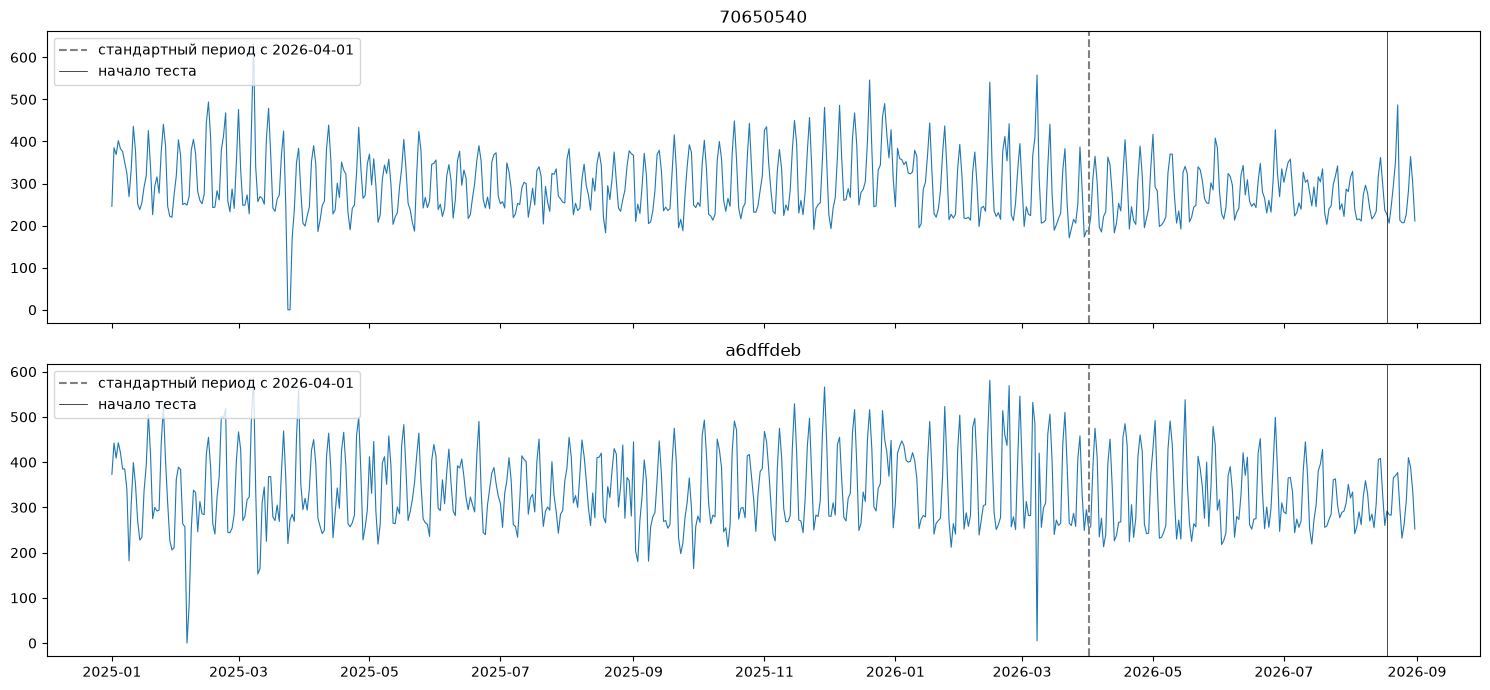

In [33]:
# Длинная история целиком: серой линией — начало стандартного периода
fig, axes = plt.subplots(len(units_long_ts.segments), 1, figsize=(15, 7), sharex=True)
for ax, segment in zip(axes, units_long_ts.segments):
    series = units_long_ts[:, segment, "target"]
    ax.plot(series.index, series.values, linewidth=0.8)
    ax.axvline(pd.Timestamp(STANDARD_START), color="grey", linestyle="--", label=f"стандартный период с {STANDARD_START}")
    ax.axvline(test_units_ts.timestamps[0], color="black", linewidth=0.5, label="начало теста")
    ax.set_title(segment)
    ax.legend(loc="upper left")
plt.tight_layout()

#### Выводы

### Шаг 3.2. Гипотеза до обучения

По тетрадям про `HoltWintersModel` и `ProphetModel` ты знаешь: тренда почти нет, недельная «пила» сильная, у `a6dffdeb` «пила» со временем сужается.

- Какие лаги подсказывает недельная сезонность при горизонте 14? Нужен ли `DifferencingTransform`?
- Посчитай: сколько строк train останется у модели после удаления строк с `NaN` при максимальном лаге 28, 56 и 364 — на стандартной и на длинной истории?
- Что может дать `DateFlagsTransform(day_number_in_week=True)` поверх лагов, кратных 7?

In [34]:
# Есть ли тренд и насколько сильна недельная «пила» — на стандартной и на длинной истории
hypothesis_rows = []
for history, train in {"standard": train_units_ts, "long": train_units_long_ts}.items():
    train_df = train.to_pandas(flatten=True)
    for segment, segment_df in train_df.groupby("segment"):
        days = (segment_df["timestamp"] - segment_df["timestamp"].min()).dt.days
        slope = np.polyfit(days, segment_df["target"], deg=1)[0]  # наклон линейного тренда, заказов в день за день
        weekday_mean = segment_df.groupby(segment_df["timestamp"].dt.day_name())["target"].mean()
        hypothesis_rows.append({
            "history": history,
            "segment": segment,
            "mean_orders": segment_df["target"].mean(),
            "trend_change_over_train": slope * days.max(),               # на сколько тренд сдвинул уровень за весь train
            "weekly_range": weekday_mean.max() - weekday_mean.min(),     # размах «пилы»: лучший день − худший
            "best_day": weekday_mean.idxmax(),
            "worst_day": weekday_mean.idxmin(),
        })

pd.DataFrame(hypothesis_rows).set_index(["history", "segment"]).round(1)

mean_orders  trend_change_over_train  weekly_range  \
history  segment                                                        
standard 70650540        276.5                      6.0         113.5   
         a6dffdeb        323.8                    -22.8         171.7   
long     70650540        295.2                    -31.0         158.3   
         a6dffdeb        338.1                     -7.6         177.8   

                   best_day worst_day  
history  segment                       
standard 70650540  Saturday   Tuesday  
         a6dffdeb  Saturday    Monday  
long     70650540  Saturday   Tuesday  
         a6dffdeb  Saturday   Tuesday

lag,14,15,16,17,18,19,20,21,22,23,...,29,30,31,32,33,34,35,357,364,371
70650540,0.7,0.38,-0.16,-0.43,-0.43,-0.14,0.39,0.68,0.36,-0.19,...,0.34,-0.19,-0.44,-0.43,-0.15,0.36,0.65,0.7,0.75,0.68
a6dffdeb,0.65,0.33,-0.19,-0.45,-0.45,-0.15,0.36,0.65,0.31,-0.21,...,0.33,-0.22,-0.49,-0.45,-0.18,0.34,0.63,0.63,0.65,0.62
same_weekday,True,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,True,True,True,True


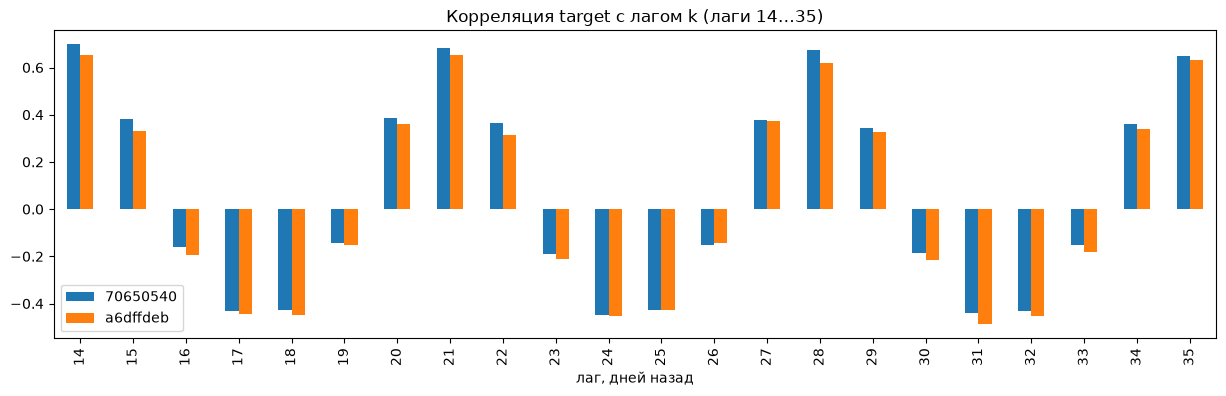

In [35]:
# Какие лаги ≥ HORIZON сильнее всего связаны с сегодняшним днём: корреляция target с лагом k (на длинном train, без теста)
candidate_lags = list(range(HORIZON, 36)) + [357, 364, 371]
lag_corr_df = pd.DataFrame({
    segment: {
        lag: train_units_long_ts[:, segment, "target"].autocorr(lag=lag)
        for lag in candidate_lags
    }
    for segment in units_long_ts.segments
})
lag_corr_df.index.name = "lag"
lag_corr_df["same_weekday"] = lag_corr_df.index % 7 == 0  # лаг кратен 7 — тот же день недели

fig, ax = plt.subplots(figsize=(15, 4))
short_corr = lag_corr_df.loc[:35, units_long_ts.segments]
short_corr.plot(kind="bar", ax=ax, title="Корреляция target с лагом k (лаги 14…35)")
ax.set_xlabel("лаг, дней назад");

lag_corr_df.round(2).T

In [36]:
# Сколько строк train останется у модели: строки, где самый длинный лаг ещё не определён, выбрасываются (раздел 1.3)
rows_left_df = pd.DataFrame({
    history: {
        f"max_lag_{max_lag}": max(len(train.timestamps) - max_lag, 0)
        for max_lag in [28, 56, 364]
    }
    for history, train in {"standard": train_units_ts, "long": train_units_long_ts}.items()
})
rows_left_df.loc["train_days"] = [len(train_units_ts.timestamps), len(train_units_long_ts.timestamps)]
rows_left_df

,standard,long
max_lag_28,111,566
max_lag_56,83,538
max_lag_364,0,230
train_days,139,594


#### Выводы

**1. Зачем смотреть на длинную историю.**
CatBoost учится на строках таблицы: одна строка — один день со своими лагами. `ProphetModel` или `HoltWintersModel` хватает пары месяцев, чтобы уловить недельный узор, а бустингу нужно много строк-примеров. На стандартном периоде их мало: 139 дней train, и часть ещё теряется из-за лагов. Остаётся порядка 12 понедельников, 12 вторников и т. д. — для модели из сотен деревьев это очень мало. Длинная история (с 2025-01-01) даёт 594 дня train вместо 139 и открывает годовой лаг 364 — «что было в этот же день год назад».


**2. Какие лаги брать: кратные 7.**
Корреляция показывает связь лагов с  `target` и позволяет выбрать признаки для модели — лишние лаги модели только мешают. Корреляция почти не падает от 14 к 35 (0.70 → 0.65): недельный узор устойчивый, и лаги 5–8 недель назад ещё полезны — вопрос, хватит ли на них истории?

**Годовой лаг 364 — сигнал слабый.** Его корреляция высокая (0.65–0.75), но 364 = 52 недели, то есть это тоже «тот же день недели». Соседние 357 и 371 дают почти столько же (0.62–0.70). Собственно годового сигнала — разница с соседями — всего 0.02–0.05.

**3. `DifferencingTransform` не нужен.**
Вместо «сколько заказов сегодня» модель прогнозирует «на сколько сегодня больше, чем тот же день неделю назад» ($y_t - y_{t-7}$), а `Pipeline` потом собирает уровень обратно сложением. Это лекарство от потолка деревьев: при тренде будущее выходит за пределы train, и прогноз упирается в потолок, а приращения остаются в знакомом диапазоне. У наших юнитов тренда практически нет:

| история | юнит | тренд за весь train | размах недельной «пилы» |
|---|---|---|---|
| стандартная | `70650540` | +6 | 114 |
| стандартная | `a6dffdeb` | −23 | 172 |
| длинная | `70650540` | −31 | 158 |
| длинная | `a6dffdeb` | −8 | 178 |

Для `a6dffdeb` за 4.5 месяца уровень сдвинулся всего на 23 заказа, а внутри обычной недели заказы гуляют на 172 — от понедельника к субботе. Ряд не растёт и не падает, он качается вокруг одного уровня. Значит, в тесте будут значения из того же диапазона, что модель уже видела в train, — в потолок упираться нечему.

А лишнее дифференцирование вредит. С ним прогноз на вторник строится как «прошлый вторник + приращение». Если в прошлый вторник случайно был провал, он скопируется в прогноз. Без дифференцирования модель смотрит сразу на несколько прошлых вторников (лаги 14, 21, 28, …), и случайность одного дня сглаживается.

**4. Сколько строк останется модели.**
Строка годится для обучения, только если у неё заполнены все лаги. В начале истории лагам не на что указывать. Пример: стандартная история начинается 1 апреля, самый длинный лаг — 56:

| день train | на что указывает `lag_56` | строка годится? |
|---|---|---|
| 1 апреля (1-й день) | 5 февраля — данных нет | ❌ выбрасывается |
| 26 мая (56-й день) | 31 марта — данных нет | ❌ |
| 27 мая (57-й день) | 1 апреля — есть | ✅ первая годная строка |

**Строк для обучения = дней train − самый длинный лаг:**

| самый длинный лаг | стандартная (139 дней) | длинная (594 дня) |
|---|---|---|
| 28 | 111 | 566 |
| 56 | 83 | 538 |
| 364 | 0 — невозможно | 230 |

Это компромисс: длинные лаги дают каждой строке больше информации, но строк становится меньше.

## Задание 4. CatBoost на двух юнитах: признаки, история, гиперпараметры

Подбираем признаки и параметры CatBoost на данных из Задания 3 и проверяем выбор через backtest. Для ориентира — holdout macro SMAPE на тех же 2 юнитах и 14 днях: `HoltWintersModel(trend=None, seasonal="add")` — 7.77, лучший `SARIMAXModel` — 7.42, `ProphetModel()` — 9.09.

### Шаг 4.1. Наборы признаков

На стандартной истории обучи `Pipeline(CatBoostPerSegmentModel(random_seed=RANDOM_SEED), transforms, HORIZON)` с наборами:
- `flags_only` — только `DateFlagsTransform(day_number_in_week=True, day_number_in_month=False, is_weekend=False)`, без лагов;
- `lags_weekly` — лаги 14, 21, …, 56 (кратные 7);
- `lags_all` — все лаги с 14-го по 56-й;
- `lags_weekly_mean` — `lags_weekly` + `MeanTransform` по `lag_14` с окнами 7 и 28;
- `lags_weekly_flags` — `lags_weekly` + `DateFlagsTransform(day_number_in_week=True, day_number_in_month=False, is_weekend=False)`.

Сделай функцию `make_feature_sets()`, которая каждый раз создаёт **новые** трансформы, — пригодится в 4.2–4.4 и в бонусе.

Собери таблицу: строки — наборы, колонки — SMAPE по юнитам, SMAPE macro и bias по юнитам.

- Какой набор лучший? Подтвердилась ли гипотеза из шага 3.2?
- Насколько `flags_only` хуже наборов с лагами? Что это говорит о наших рядах (раздел 1.1, «А если без лагов»)?
- Где CatBoost оказался относительно `HoltWintersModel` и `ProphetModel`?

In [37]:
WEEKLY_LAGS = list(range(HORIZON, 57, 7))  # 14, 21, …, 56 — тот же день недели (шаг 3.2)


def make_feature_sets() -> dict:
    """Наборы признаков: имя → список трансформов. Функция создаёт трансформы ЗАНОВО — пригодится в 4.2–4.4 и в бонусе."""
    def weekly_lags():
        return LagTransform(in_column="target", lags=WEEKLY_LAGS, out_column="lag")

    def day_of_week():
        return DateFlagsTransform(day_number_in_week=True, day_number_in_month=False, is_weekend=False, out_column="flag")

    return {
        "flags_only": [day_of_week()],                                                    # без лагов (раздел 1.1)
        "lags_weekly": [weekly_lags()],
        "lags_all": [LagTransform(in_column="target", lags=list(range(HORIZON, 57)), out_column="lag")],
        "lags_weekly_mean": [
            weekly_lags(),
            MeanTransform(in_column=f"lag_{HORIZON}", window=7, out_column="mean_7"),    # уровень за неделю
            MeanTransform(in_column=f"lag_{HORIZON}", window=28, out_column="mean_28"),  # уровень за 4 недели
        ],
        "lags_weekly_flags": [weekly_lags(), day_of_week()],
    }


forecasts_sets = {}
for name, transforms in make_feature_sets().items():
    pipeline = Pipeline(CatBoostPerSegmentModel(random_seed=RANDOM_SEED), transforms=transforms, horizon=HORIZON)
    pipeline.fit(train_units_ts)
    forecasts_sets[name] = pipeline.forecast()

list(forecasts_sets)

/Users/skv/projects-skv/study-etna/.venv/lib/python3.11/site-packages/etna/datasets/utils.py:190: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_long["segment"] = np.repeat(a=segments, repeats=n_timestamps)
/Users/skv/projects-skv/study-etna/.venv/lib/python3.11/site-packages/etna/datasets/utils.py:190: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_long["segment"] = np.repeat(a=segments, repeats=n_timestamps)
/Users/skv/projects-skv/study-etna/.venv/lib/python3.11/site-packages/etna/datasets/utils.py:1

['flags_only',
 'lags_weekly',
 'lags_all',
 'lags_weekly_mean',
 'lags_weekly_flags']

In [38]:
# SMAPE и bias по каждому юниту + SMAPE macro — одна строка на набор признаков
sets_rows = []
for name, forecast_ts in forecasts_sets.items():
    smape_per_segment = SMAPE(mode="per-segment")(y_true=test_units_ts, y_pred=forecast_ts)
    sets_rows.append({
        "features": name,
        **{f"smape_{segment}": value for segment, value in smape_per_segment.items()},
        "smape_macro": SMAPE(mode="macro")(y_true=test_units_ts, y_pred=forecast_ts),
        # bias, %: > 0 — прогноз выше факта, < 0 — ниже
        **{f"bias_{segment}": value for segment, value in bias(y_true=test_units_ts, y_pred=forecast_ts).items()},
    })

sets_df = pd.DataFrame(sets_rows).set_index("features")
sets_df["rank"] = sets_df["smape_macro"].rank().astype(int)  # 1 — лучший по macro
# Для ориентира, holdout macro на тех же 2 юнитах: HoltWintersModel(trend=None, seasonal="add") — 7.77,
# лучший SARIMAXModel — 7.42, ProphetModel() — 9.09
sets_df.sort_values("rank").round(2)

,smape_70650540,smape_a6dffdeb,smape_macro,bias_70650540,bias_a6dffdeb,rank
features,,,,,,
flags_only,11.57,7.91,9.74,1.23,0.62,1
lags_weekly_flags,12.34,7.34,9.84,0.57,-2.60,2
lags_weekly,12.89,7.06,9.98,0.16,-2.83,3
lags_all,15.77,7.87,11.82,2.73,-3.15,4
lags_weekly_mean,16.07,7.66,11.87,5.32,-3.64,5


лучший набор: flags_only


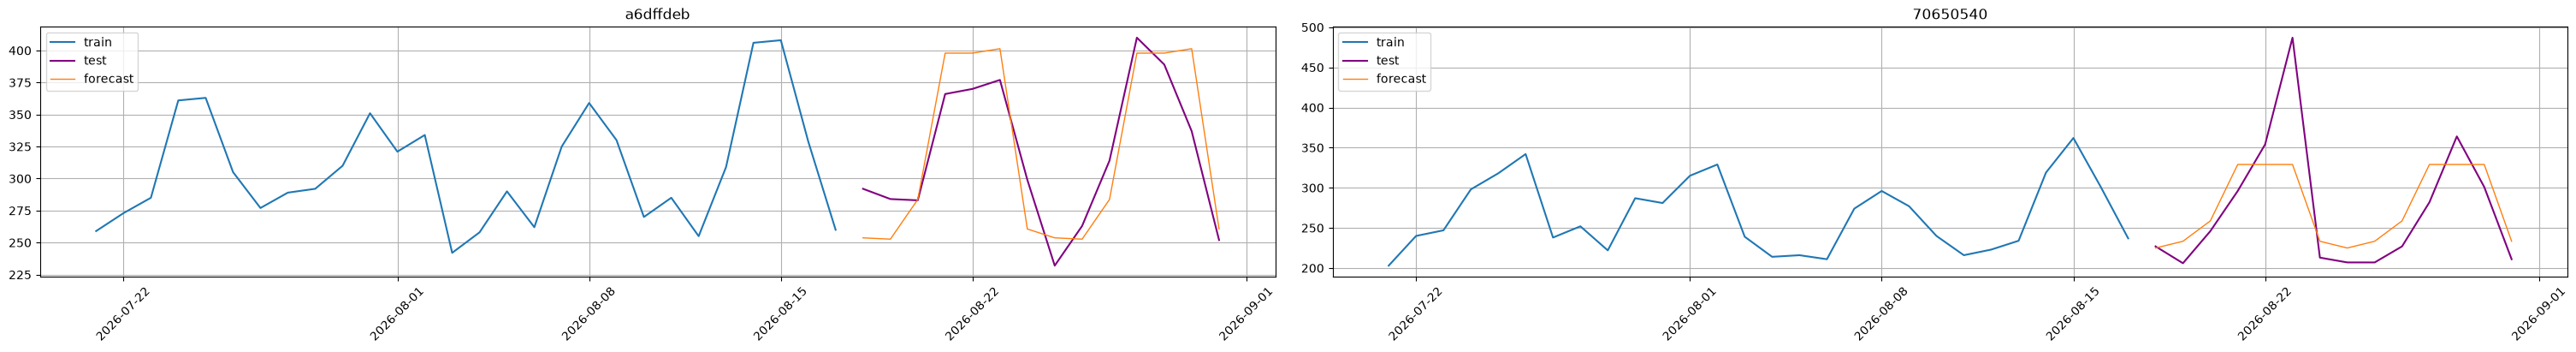

In [39]:
# Лучший набор: прогноз на тесте
best_set = sets_df["smape_macro"].idxmin()
print(f"лучший набор: {best_set}")

plot_forecast(
    forecast_ts=forecasts_sets[best_set],
    test_ts=test_units_ts,
    train_ts=train_units_ts,
    n_train_samples=4 * 7,
    figsize=(15, 4),
)

In [40]:
# CatBoost случаен: разный random_seed — разный прогноз. Повторяем с 5 сидами, чтобы отличить разницу наборов от шума модели
SEEDS = [1, 2, 3, 7, 42]
seed_rows = []
for seed in SEEDS:
    for name, transforms in make_feature_sets().items():
        pipeline = Pipeline(CatBoostPerSegmentModel(random_seed=seed), transforms=transforms, horizon=HORIZON)
        pipeline.fit(train_units_ts)
        seed_rows.append({
            "features": name,
            "seed": seed,
            "smape_macro": SMAPE(mode="macro")(y_true=test_units_ts, y_pred=pipeline.forecast()),
        })

(
    pd.DataFrame(seed_rows)
    .groupby("features")["smape_macro"]
    .agg(["mean", "min", "max", "std"])
    .sort_values("mean")
    .round(2)
)

/Users/skv/projects-skv/study-etna/.venv/lib/python3.11/site-packages/etna/datasets/utils.py:190: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_long["segment"] = np.repeat(a=segments, repeats=n_timestamps)
/Users/skv/projects-skv/study-etna/.venv/lib/python3.11/site-packages/etna/datasets/utils.py:190: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_long["segment"] = np.repeat(a=segments, repeats=n_timestamps)
/Users/skv/projects-skv/study-etna/.venv/lib/python3.11/site-packages/etna/datasets/utils.py:1

,mean,min,max,std
features,,,,
lags_weekly_flags,9.82,9.65,10.05,0.15
lags_weekly,9.96,9.90,10.09,0.08
flags_only,10.24,9.41,12.24,1.14
lags_all,11.40,11.16,11.82,0.26
lags_weekly_mean,11.67,11.39,11.87,0.21


#### Выводы

CatBoost случаен: даже с одним `random_seed` числа от запуска к запуску немного плавают, а с разными сидами — заметно. Поэтому ниже — средние по 5 сидам (последняя ячейка), числа приблизительные.

| набор | SMAPE macro (среднее по 5 сидам) | разброс по сидам | итог |
|---|---|---|---|
| `lags_weekly` | **~9.9** | 9.8 … 10.0 | лучший и самый стабильный |
| `lags_weekly_flags` | ~10.0 | 9.8 … 10.3 | то же, что `lags_weekly` |
| `flags_only` | ~10.2 | **9.4 … 12.2** | в среднем чуть хуже, но лотерея |
| `lags_all` | ~11.4 | 11.1 … 11.6 | стабильно хуже |
| `lags_weekly_mean` | ~11.8 | 11.6 … 12.1 | стабильно хуже |

**Лучший набор** — лаги, кратные 7 (14, 21, …, 56). День недели поверх них ничего не добавил: разница 0.1 меньше разброса по сидам. Лаги и так «знают», какой это день.

**Больше признаков — хуже.**
- `lags_all` (43 лага) хуже `lags_weekly` (7 лагов) на ~1.5. Строк в train — всего 83 (шаг 3.2), а признаков — 43, и 36 из них — «соседние дни», почти бесполезные (шаг 2.4). Модель находит в них случайные закономерности, которых нет в тесте. Чем короче история, тем дороже каждый лишний признак.
- `lags_weekly_mean` хуже на ~1.9, и почти весь проигрыш — на `70650540` (SMAPE ~16 против ~13) с перекосом вверх: bias около +5% против ~0% у `lags_weekly`. Среднее за 4 недели — это уровень 2–6 недель назад. Если с тех пор уровень снизился, этот признак тянет прогноз вверх, к старому уровню.

**`flags_only` — в среднем почти как лаги, но ненадёжный.** Как и ожидали в разделе 1.1: ряд без тренда, поэтому «средний понедельник, средняя суббота…» уже неплохой прогноз. Но у модели один признак из 7 значений, и итог сильно зависит от случайности: от 9.4 до 12.2 в зависимости от сида. С лагами модель устойчивее.

**По юнитам картина разная.** У `a6dffdeb` SMAPE 7–8, у `70650540` — 12–16 у всех наборов.

**С прошлыми моделями CatBoost пока не конкурирует.** Holdout SMAPE macro (среднее по 2 юнитам) хуже прошлых моделей и это ожидаемо(!). В рядах нет ничего, кроме уровня и недельного узора, а это лучше всего умеют модели, которые описывают узор напрямую. Лаги дают CatBoost ту же информацию, только с опозданием на 2+ недели.
- `SARIMAXModel` — 7.42
- `HoltWintersModel` — 7.77
- `ProphetModel()` — 9.09
- `CatBoost()` — ~9.9.

### Шаг 4.2. Длина истории

Повтори 2 лучших набора из шага 4.1 на длинной истории (с 2025-01-01). Добавь ещё один вариант, невозможный на стандартной истории, — лучший набор + годовой лаг `364`.

Для каждого варианта выведи, на скольких строках модель реально училась.

- Помогла ли длинная история? Одинаково ли на обоих юнитах?
- Что дал годовой лаг?

In [41]:
# Варианты: (история, набор признаков). Трансформы создаются заново на каждый вызов
def make_history_variants() -> dict:
    sets = make_feature_sets()
    return {
        "standard_lags_weekly": (train_units_ts, sets["lags_weekly"]),
        "standard_lags_weekly_flags": (train_units_ts, sets["lags_weekly_flags"]),
        "long_lags_weekly": (train_units_long_ts, sets["lags_weekly"]),
        "long_lags_weekly_flags": (train_units_long_ts, sets["lags_weekly_flags"]),
        # годовой лаг возможен только на длинной истории (шаг 3.2)
        "long_lags_weekly_364": (train_units_long_ts, [LagTransform(in_column="target", lags=WEEKLY_LAGS + [364], out_column="lag")]),
    }


# Сразу по 5 сидам (шаг 4.1: разница между вариантами может быть меньше шума модели)
history_rows = []
forecasts_history = {}  # прогнозы с RANDOM_SEED — для графика
for seed in SEEDS:
    for name, (train, transforms) in make_history_variants().items():
        pipeline = Pipeline(CatBoostPerSegmentModel(random_seed=seed), transforms=transforms, horizon=HORIZON)
        pipeline.fit(train)
        forecast_ts = pipeline.forecast()
        if seed == RANDOM_SEED:
            forecasts_history[name] = forecast_ts
        history_rows.append({
            "variant": name,
            "seed": seed,
            "smape_macro": SMAPE(mode="macro")(y_true=test_units_ts, y_pred=forecast_ts),
            **{f"smape_{segment}": value for segment, value in SMAPE()(y_true=test_units_ts, y_pred=forecast_ts).items()},
            **{f"bias_{segment}": value for segment, value in bias(y_true=test_units_ts, y_pred=forecast_ts).items()},
        })

history_runs_df = pd.DataFrame(history_rows)
len(history_runs_df)

/Users/skv/projects-skv/study-etna/.venv/lib/python3.11/site-packages/etna/datasets/utils.py:190: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_long["segment"] = np.repeat(a=segments, repeats=n_timestamps)
/Users/skv/projects-skv/study-etna/.venv/lib/python3.11/site-packages/etna/datasets/utils.py:190: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_long["segment"] = np.repeat(a=segments, repeats=n_timestamps)
/Users/skv/projects-skv/study-etna/.venv/lib/python3.11/site-packages/etna/datasets/utils.py:1

25

In [42]:
# На скольких строках модель реально училась: строки, где самый длинный лаг ещё NaN, выбрасываются
train_rows = {}
for name, (train, transforms) in make_history_variants().items():
    features_ts = deepcopy(train)
    features_ts.fit_transform(transforms)
    features_df = features_ts.to_pandas(flatten=True)
    train_rows[name] = len(features_df.dropna()) // len(features_ts.segments)  # строк на один юнит

# Средние по 5 сидам + разброс macro + строки train
history_df = history_runs_df.drop(columns="seed").groupby("variant").mean()
history_df["smape_macro_min"] = history_runs_df.groupby("variant")["smape_macro"].min()
history_df["smape_macro_max"] = history_runs_df.groupby("variant")["smape_macro"].max()
history_df["train_rows_per_unit"] = pd.Series(train_rows)
history_df.sort_values("smape_macro").round(2)

/Users/skv/projects-skv/study-etna/.venv/lib/python3.11/site-packages/etna/datasets/utils.py:190: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_long["segment"] = np.repeat(a=segments, repeats=n_timestamps)
/Users/skv/projects-skv/study-etna/.venv/lib/python3.11/site-packages/etna/datasets/utils.py:190: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_long["segment"] = np.repeat(a=segments, repeats=n_timestamps)


,smape_macro,smape_70650540,smape_a6dffdeb,bias_70650540,bias_a6dffdeb,smape_macro_min,smape_macro_max,train_rows_per_unit
variant,,,,,,,,
long_lags_weekly_364,9.82,10.86,8.77,-0.93,-2.65,9.41,10.02,230
standard_lags_weekly_flags,9.82,12.34,7.30,0.22,-3.11,9.65,10.05,83
long_lags_weekly,9.93,11.71,8.15,-1.24,2.12,9.76,10.08,538
standard_lags_weekly,9.96,12.76,7.16,-0.00,-2.47,9.90,10.09,83
long_lags_weekly_flags,10.19,11.99,8.39,-0.28,3.61,9.96,10.42,538


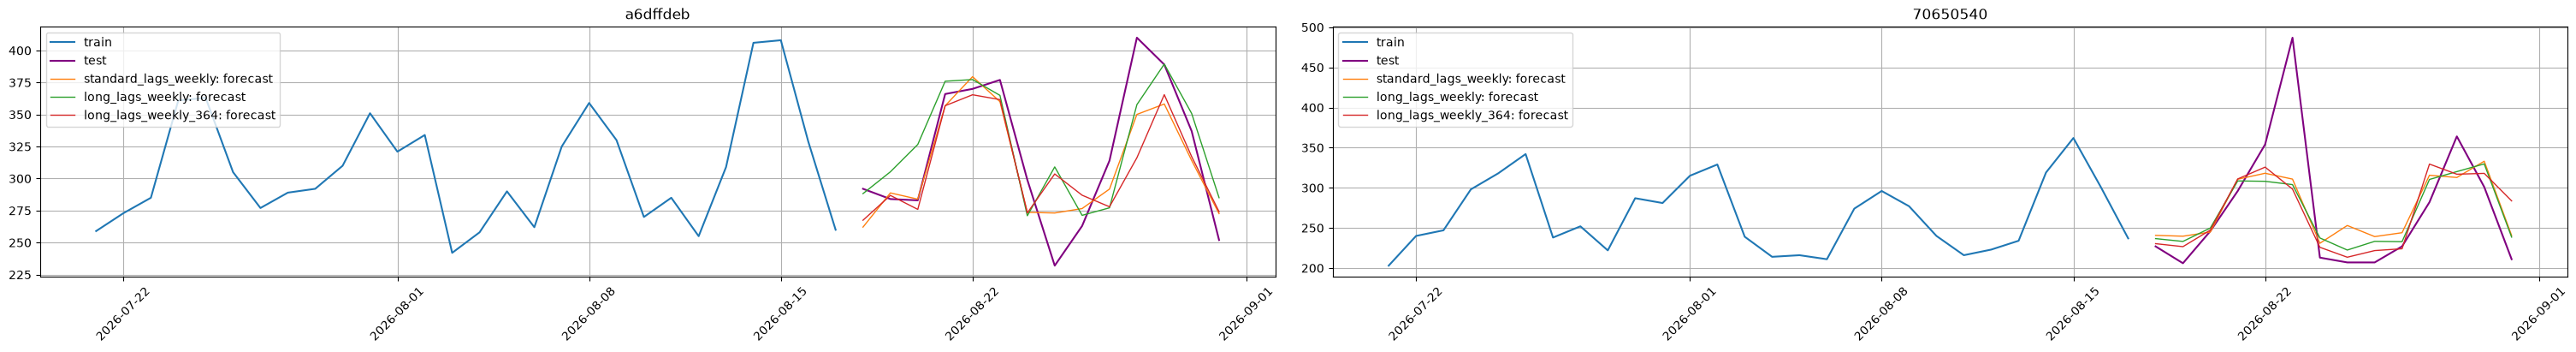

In [43]:
# Стандартная против длинной истории на одном графике (набор lags_weekly, сид RANDOM_SEED)
plot_forecast(
    forecast_ts={name: forecasts_history[name] for name in ["standard_lags_weekly", "long_lags_weekly", "long_lags_weekly_364"]},
    test_ts=test_units_ts,
    train_ts=train_units_ts,
    n_train_samples=4 * 7,
    figsize=(15, 4),
)

#### Выводы
Числа — средние по 5 сидам, приблизительные.

| вариант | строк train на юнит | SMAPE macro | `70650540` | `a6dffdeb` | bias `a6dffdeb` |
|---|---|---|---|---|---|
| стандартная, `lags_weekly` | 83 | **~9.7** | ~12.5 | **~6.9** | ~−3% |
| стандартная, `lags_weekly_flags` | 83 | ~9.8 | ~12.4 | ~7.3 | ~−3% |
| длинная, `lags_weekly` | 538 | ~10.0 | ~11.9 | ~8.0 | ~+2% |
| длинная, `lags_weekly_flags` | 538 | ~10.1 | ~11.6 | ~8.7 | ~+4% |
| длинная, `lags_weekly` + 364 | 230 | ~10.2 | **~11.0** | ~9.3 | ~−3% |

**В среднем длинная история не помогла.** Macro у всех вариантов 9.7–10.2, а разброс одного варианта по сидам — около 0.5. Победителя по macro нет. В 6 раз больше строк train — и никакого выигрыша.

**Но по юнитам эффект противоположный — и он реальный** (диапазоны по сидам не пересекаются):
- **`70650540` от длинной истории выигрывает:** 12.5 → 11.9, а с годовым лагом — 11.0, лучший результат для этого юнита во всём задании.
- **`a6dffdeb` проигрывает:** 6.9 → 8.0, с годовым лагом — 9.3. Bias сменил знак: прогноз стал выше факта (около +2…+4%).

Среднее по двум юнитам эти эффекты взаимно гасит. **Macro прячет, что одно и то же решение одному юниту помогает, а другому вредит.**

**Почему так.** Длинная история учит модель «как было в 2025 году» — а это не всегда «как сейчас»:
- у `a6dffdeb` раньше уровень был выше (в среднем за длинный train ~338 заказов против ~324 за стандартный, шаг 3.2), а недельная «пила» со временем сужалась (тетради про `HoltWintersModel` и `ProphetModel`). Старые примеры тянут прогноз к старому, более высокому уровню — отсюда перелёт;
- у `70650540` прошлогоднее поведение, видимо, лучше похоже на нынешнее: годовой лаг подсказывает, «что было в эти же дни год назад», и прогноз точнее.

**Годовой лаг — тоже по-разному.** Сигнал в нём небольшой (шаг 3.2), а цена большая: модель теряет 308 строк из 538 (учится только на днях, у которых есть «год назад»). Для `70650540` это окупилось, для `a6dffdeb` — нет.

**Что берём дальше.** Стандартную историю с `lags_weekly`: в среднем не хуже остальных, самый простой вариант, и сравним напрямую с прошлыми моделями. Но вывод «длинная история не нужна» по одному окну в 14 дней на 2 юнитах делать рано. Длина истории — кандидат на проверку через backtest и на 10 юнитах.

### Шаг 4.3. Гиперпараметры на валидационной выборке

Раздели train ещё раз: последние 14 дней train — **valid**, остальное — обучение. Test по-прежнему последние 14 дней ряда, на подборе его не трогаем.

С лучшим набором признаков перебрать сетку `depth` ∈ {4, 6, 8} × `learning_rate` ∈ {0.03, 0.1} (`iterations=500`, `random_seed=RANDOM_SEED`): обучай на train без valid, считай SMAPE macro на valid.

- Какая комбинация лучшая на valid, а какая на test? Совпали ли?
- Насколько разница между комбинациями больше или меньше разницы между valid и test одной и той же комбинации?

In [44]:
# Три части: fit (обучение) → valid (подбор, последние 14 дней train) → test (последние 14 дней ряда, только для проверки)
fit_units_ts, valid_units_ts = train_units_ts.train_test_split(test_size=HORIZON)

pd.DataFrame({
    name: {"start": ts_part.timestamps.min().date(), "end": ts_part.timestamps.max().date(), "days": len(ts_part.timestamps)}
    for name, ts_part in {"fit": fit_units_ts, "valid": valid_units_ts, "test": test_units_ts}.items()
}).T

,start,end,days
fit,2026-04-01,2026-08-03,125
valid,2026-08-04,2026-08-17,14
test,2026-08-18,2026-08-31,14


In [45]:
# Сетка depth × learning_rate (+ параметры CatBoost по умолчанию для сравнения), набор признаков — lags_weekly
param_grid = [{"depth": depth, "learning_rate": learning_rate, "iterations": 500} for depth in [4, 6, 8] for learning_rate in [0.03, 0.1]]
param_grid.append({})  # {} — по умолчанию: depth=6, iterations=1000, learning_rate подбирает CatBoost


def params_name(params: dict) -> str:
    return "default" if not params else f"depth_{params['depth']}_lr_{params['learning_rate']}"


def fit_forecast_smape(train: TSDataset, test: TSDataset, params: dict, seed: int) -> float:
    pipeline = Pipeline(
        CatBoostPerSegmentModel(random_seed=seed, **params),
        transforms=make_feature_sets()["lags_weekly"],
        horizon=HORIZON,
    )
    pipeline.fit(train)
    return SMAPE(mode="macro")(y_true=test, y_pred=pipeline.forecast())


# Для каждой комбинации и каждого сида: valid (обучение на fit) и test (обучение на всём train) — test только ради эксперимента
grid_rows = []
for seed in SEEDS:
    for params in param_grid:
        grid_rows.append({
            "params": params_name(params),
            "seed": seed,
            "smape_valid": fit_forecast_smape(fit_units_ts, valid_units_ts, params, seed),
            "smape_test": fit_forecast_smape(train_units_ts, test_units_ts, params, seed),
        })

grid_runs_df = pd.DataFrame(grid_rows)
len(grid_runs_df)

35

In [46]:
# Средние по 5 сидам: совпадает ли лучший на valid с лучшим на test?
grid_df = grid_runs_df.groupby("params")[["smape_valid", "smape_test"]].mean()
grid_df["valid_std_by_seed"] = grid_runs_df.groupby("params")["smape_valid"].std()
grid_df["test_std_by_seed"] = grid_runs_df.groupby("params")["smape_test"].std()
grid_df["test_minus_valid"] = grid_df["smape_test"] - grid_df["smape_valid"]
grid_df["rank_valid"] = grid_df["smape_valid"].rank().astype(int)
grid_df["rank_test"] = grid_df["smape_test"].rank().astype(int)
grid_df.sort_values("rank_valid").round(2)

,smape_valid,smape_test,valid_std_by_seed,test_std_by_seed,test_minus_valid,rank_valid,rank_test
params,,,,,,,
depth_8_lr_0.1,9.37,10.45,0.25,0.32,1.08,1,7
default,9.58,9.96,0.35,0.08,0.38,2,5
depth_8_lr_0.03,9.59,10.32,0.30,0.21,0.73,3,6
depth_6_lr_0.03,9.60,9.84,0.29,0.23,0.24,4,3
depth_4_lr_0.03,9.63,9.66,0.30,0.32,0.03,5,2
depth_6_lr_0.1,9.74,9.95,0.37,0.51,0.22,6,4
depth_4_lr_0.1,9.98,9.37,0.20,0.37,-0.61,7,1


In [47]:
# Масштабы: разница между комбинациями против разницы между valid и test одной комбинации
scale_df = pd.Series({
    "valid: лучшая − худшая комбинация": grid_df["smape_valid"].max() - grid_df["smape_valid"].min(),
    "test: лучшая − худшая комбинация": grid_df["smape_test"].max() - grid_df["smape_test"].min(),
    "|test − valid| одной комбинации, в среднем": grid_df["test_minus_valid"].abs().mean(),
    "разброс по сидам (std), в среднем": grid_df[["valid_std_by_seed", "test_std_by_seed"]].mean().mean(),
}, name="smape").round(2)
scale_df

valid: лучшая − худшая комбинация             0.61
test: лучшая − худшая комбинация              1.08
|test − valid| одной комбинации, в среднем    0.47
разброс по сидам (std), в среднем             0.29
Name: smape, dtype: float64

#### Выводы

> Числа — средние по 5 сидам, приблизительные.

**Как устроен подбор.** Train разрезан ещё раз: **fit** (125 дней) → **valid** (14 дней, 08-04 … 08-17) → **test** (14 дней, 08-18 … 08-31). Подбираем по valid, test в жизни открываем один раз в конце. Здесь мы посчитали test для всех комбинаций только ради эксперимента — проверить, можно ли верить valid.

| параметры | valid | test | ранг valid → test |
|---|---|---|---|
| `depth=4, lr=0.03` | **~9.5** | **~9.4** | 1 → 1 |
| `depth=6, lr=0.03` | ~9.5 | ~9.9 | 2 → 4 |
| по умолчанию (`depth=6`, 1000 деревьев) | ~9.6 | ~9.8 | 3 → 3 |
| `depth=8, lr=0.03` | ~9.6 | ~10.1 | 4 → 6 |
| `depth=4, lr=0.1` | ~9.6 | ~9.7 | 5 → 2 |
| `depth=6, lr=0.1` | ~9.6 | ~10.0 | 6 → 5 |
| `depth=8, lr=0.1` | ~9.6 | ~10.1 | 7 → 7 |

**Лучший на valid и на test совпал (`depth=4, lr=0.03`) — но во многом повезло.** На valid все 7 комбинаций уложились в **0.16** SMAPE, а шум от сида — около **0.28**. То есть valid почти не различает комбинации: первое и второе место там — ничья (9.47 и 9.47). По одному valid-окну выбор фактически случайный.

**Масштабы — главный вывод шага:**

| что сравниваем | разница SMAPE |
|---|---|
| лучшая − худшая комбинация на valid | ~0.2 |
| шум от `random_seed` (std) | ~0.3 |
| valid против test одной и той же комбинации | ~0.3 |
| лучшая − худшая комбинация на test | ~0.7 |

Разница между гиперпараметрами на valid **меньше шума модели** и **меньше разницы между двумя соседними окнами** по 14 дней. Подбирать гиперпараметры по одному окну на 2 юнитах — значит подбирать по шуму.

**Одна закономерность всё же видна — на test:** чем мельче деревья, тем лучше (`depth` 4 < 6 < 8 при обоих `learning_rate`). Это логично: в обучении всего ~70–80 строк на юнит, и глубокое дерево (`depth=8` — 256 листьев) просто запоминает train. Простая модель на маленьких данных обобщает лучше.

**Сколько это дало.** `depth=4, lr=0.03` против параметров по умолчанию — около −0.4 SMAPE на test (9.4 против 9.8). Меньше, чем дал выбор признаков в шаге 4.1 (~1.5–2), и далеко от `HoltWintersModel` (7.77). **Признаки и данные важнее гиперпараметров.**

**Что берём дальше:** `lags_weekly` + `depth=4, learning_rate=0.03, iterations=500` — и проверяем его не на одном окне, а через backtest.

### Шаг 4.4. Backtest: CatBoost против прошлых моделей

Прогони через `backtest` (`n_folds=5`, `mode="expand"`) на стандартной истории:
- 2–3 лучших варианта CatBoost из шагов 4.1–4.3;
- `ProphetModel(growth="flat")` — лучший Prophet по backtest;
- `HoltWintersModel(trend=None, seasonal="add", seasonal_periods=7)`.

Сравни holdout (последний фолд) и среднее по 5 фолдам, как в тетради про `ProphetModel`.

- Сохраняется ли порядок моделей?
- Выиграл ли CatBoost хоть один фолд? Что ему мешает на этих рядах — вспомни разделы 1.1 и 1.3?

In [48]:
# Лучшие параметры из шага 4.3
TUNED_PARAMS = {"depth": 4, "learning_rate": 0.03, "iterations": 500}


def make_backtest_models(seed: int = RANDOM_SEED) -> dict:
    """Имя → (ряд для backtest, модель, трансформы). Всё создаётся заново."""
    return {
        "catboost_default": (units_ts, CatBoostPerSegmentModel(random_seed=seed), make_feature_sets()["lags_weekly"]),
        "catboost_tuned": (units_ts, CatBoostPerSegmentModel(random_seed=seed, **TUNED_PARAMS), make_feature_sets()["lags_weekly"]),
        # длинная история (шаг 4.2): фолды те же — 5 последних окон по 14 дней, но train каждого фолда длиннее
        "catboost_tuned_long": (units_long_ts, CatBoostPerSegmentModel(random_seed=seed, **TUNED_PARAMS), make_feature_sets()["lags_weekly"]),
        "prophet_flat": (units_ts, ProphetModel(growth="flat"), []),
        "holt_winters": (units_ts, HoltWintersModel(trend=None, seasonal="add", seasonal_periods=7), []),
    }


# Backtest: 5 фолдов × 14 дней, expand. CatBoost — по 5 сидам, Prophet и ETS детерминированы — один раз
backtest_rows = []
for seed in SEEDS:
    for name, (ts_bt, model, transforms) in make_backtest_models(seed).items():
        if not name.startswith("catboost") and seed != SEEDS[0]:
            continue
        result_bt = Pipeline(model=model, transforms=transforms, horizon=HORIZON).backtest(
            ts=ts_bt,
            metrics=[SMAPE()],
            n_folds=5,
            mode="expand",
            joblib_params=dict(verbose=0),
        )
        fold_smape = result_bt["metrics"].groupby("fold_number")["SMAPE"].mean()  # среднее по 2 юнитам
        backtest_rows += [{"model": name, "seed": seed, "fold_number": fold, "smape": value} for fold, value in fold_smape.items()]

backtest_runs_df = pd.DataFrame(backtest_rows)

# SMAPE по фолдам (среднее по юнитам и сидам): строки — фолды, колонки — модели
smape_folds_df = backtest_runs_df.pivot_table(index="fold_number", columns="model", values="smape", aggfunc="mean")
smape_folds_df.round(2)

model,catboost_default,catboost_tuned,catboost_tuned_long,holt_winters,prophet_flat
fold_number,,,,,
0,11.35,11.32,11.36,11.19,11.19
1,9.12,9.44,7.98,7.51,7.00
2,11.38,11.73,9.54,10.05,9.90
3,9.58,9.63,8.47,7.96,8.49
4,9.96,9.66,9.75,7.77,9.22


In [49]:
# Holdout (последний фолд) против среднего по 5 фолдам — как в тетради про ProphetModel
holdout_vs_backtest = pd.DataFrame({
    "holdout_smape_macro": smape_folds_df.iloc[-1],   # последний фолд = holdout из шагов 4.1–4.3
    "backtest_smape_macro": smape_folds_df.mean(),
    "backtest_smape_std": smape_folds_df.std(),       # разброс между фолдами
    "backtest_smape_min": smape_folds_df.min(),
    "backtest_smape_max": smape_folds_df.max(),
})
holdout_vs_backtest["holdout_rank"] = holdout_vs_backtest["holdout_smape_macro"].rank().astype(int)
holdout_vs_backtest["backtest_rank"] = holdout_vs_backtest["backtest_smape_macro"].rank().astype(int)
holdout_vs_backtest["folds_won"] = smape_folds_df.idxmin(axis=1).value_counts().reindex(smape_folds_df.columns, fill_value=0)
holdout_vs_backtest.sort_values("backtest_rank").round(2)

,holdout_smape_macro,backtest_smape_macro,backtest_smape_std,backtest_smape_min,backtest_smape_max,holdout_rank,backtest_rank,folds_won
model,,,,,,,,
holt_winters,7.77,8.90,1.63,7.51,11.19,1,1,3
prophet_flat,9.22,9.16,1.57,7.00,11.19,2,2,1
catboost_tuned_long,9.75,9.42,1.31,7.98,11.36,4,3,1
catboost_default,9.96,10.28,1.03,9.12,11.38,5,4,0
catboost_tuned,9.66,10.36,1.08,9.44,11.73,3,5,0


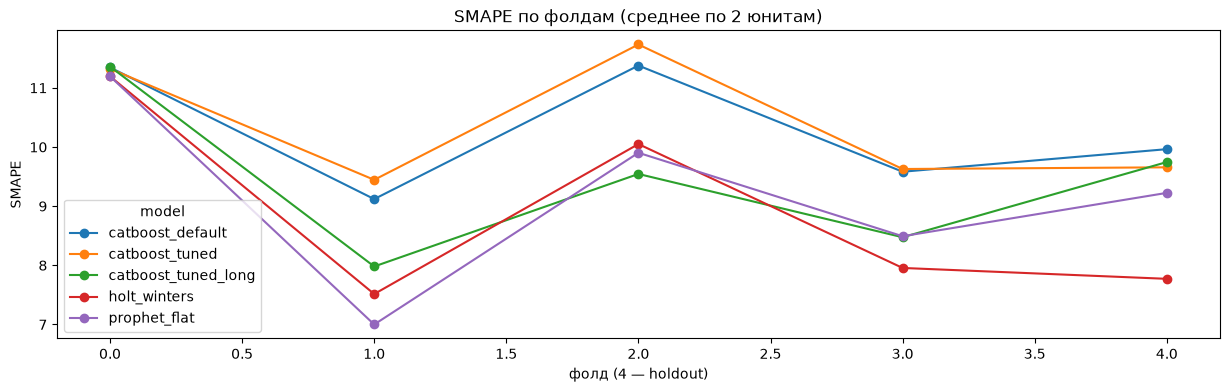

In [50]:
# SMAPE по фолдам на одном графике: где CatBoost отстаёт сильнее всего
ax = smape_folds_df.plot(marker="o", figsize=(15, 4), title="SMAPE по фолдам (среднее по 2 юнитам)")
ax.set_xlabel("фолд (4 — holdout)")
ax.set_ylabel("SMAPE");

#### Выводы

> SMAPE CatBoost — средние по 5 сидам, приблизительные. Prophet и ETS детерминированы (числа совпадают с тетрадью про `ProphetModel`).

| модель | holdout (фолд 4) | среднее по 5 фолдам | ранг holdout → backtest | фолдов выиграла |
|---|---|---|---|---|
| `holt_winters` | **7.77** | **8.90** | 1 → 1 | 3 |
| `prophet_flat` | 9.22 | 9.16 | 2 → 2 | 1 |
| `catboost_tuned_long` | ~9.8 | **~9.4** | 4 → 3 | 1 |
| `catboost_default` | ~9.8 | ~10.3 | 5 → 4 | 0 |
| `catboost_tuned` | ~9.5 | ~10.3 | 3 → 5 | 0 |

**1. CatBoost не обогнал прошлые модели.** Лучший вариант — `catboost_tuned_long` — третий: ~9.4 против 8.90 у `HoltWintersModel` и 9.16 у Prophet. Выиграл 1 фолд из 5 (фолд 2). На этих рядах (уровень + недельный узор, без тренда, без внешних факторов) бустингу нечего добавить к моделям, которые описывают узор напрямую.

**2. Подбор гиперпараметров по valid не перенёсся.** На holdout `catboost_tuned` лучше `default` (9.5 против 9.8), а по 5 фолдам — нет (10.3 и 10.3). Разница между параметрами меньше шума, и «лучшая» комбинация лучшая только на своём окне.

**3. Длинная история — главная находка шага.** На holdout в шаге 4.2 она выглядела бесполезной, а в backtest даёт ~−0.9 SMAPE (9.4 против 10.3), и это устойчиво по всем сидам (9.3…9.5 против 10.2…10.4). Причина — в ранних фолдах:

| фолд | train стандартной истории | строк для обучения (лаги до 56) | `catboost_tuned` | `catboost_tuned_long` |
|---|---|---|---|---|
| 0 | 83 дня | **27** | ~11.2 | ~11.4 |
| 1 | 97 дней | **41** | ~9.4 | **~7.8** |
| 2 | 111 дней | 55 | ~11.7 | **~9.6** |
| 3 | 125 дней | 69 | ~9.9 | ~8.5 |
| 4 (holdout) | 139 дней | 83 | ~9.5 | ~9.8 |

На стандартной истории в ранних фолдах модель учится на 27–55 строках — это 4–8 недель, по несколько примеров на каждый день недели. На длинной — 470+ строк в любом фолде. Holdout — это самый «сытый» фолд для стандартной истории, поэтому там разницы и не было видно. **Чем меньше данных, тем сильнее CatBoost от них зависит**, — в отличие от `HoltWintersModel`, которой хватает пары недель.

**4. Фолд 0 одинаково трудный для всех** (11.2–11.4 у всех пяти моделей) — дело в самом окне, а не в моделях.

**5. Holdout опять обманул бы.** По holdout `catboost_tuned` — третий и лучший CatBoost, `catboost_tuned_long` — худший CatBoost. По backtest — наоборот. Тот же урок, что в тетради про `ProphetModel`: модели с разницей меньше 1 SMAPE по одному окну не сравниваем.

**Итог:** CatBoost берём с `lags_weekly` и **длинной историей**. Параметры — по умолчанию (подбор не дал устойчивого выигрыша). Но на 10 юнитах есть проблема: у трёх юнитов в 2025 году сотни нулевых дней (раздел 2), поэтому остаёмся на стандартной истории — и проверяем другое преимущество бустинга: одну модель на все юниты.

## Бонус. Все 10 юнитов: `PerSegment` против `MultiSegment` + логирование

Главное преимущество бустинга, которое на 2 юнитах не проявить, — одна модель на много рядов. Проверяем его на всех 10 юнитах и логируем в MLflow, чтобы CatBoost встал в одну таблицу с прошлыми моделями.

### Шаг Б.1. Все 10 юнитов: holdout и метрики

На стандартном периоде (с 2026-04-01, все 10 юнитов) с лучшим набором признаков из Задания 4 обучи:
- `CatBoostPerSegmentModel` — отдельная модель на юнит;
- `CatBoostMultiSegmentModel` — одна модель на все юниты;
- `CatBoostMultiSegmentModel` + `SegmentEncoderTransform()` — одна модель, которая знает, какой это юнит.

Посчитай весь набор метрик на holdout — `SMAPE`, `WAPE`, `MAPE`, `MAE`, `Bias` (через `src/prod_metrics.py`), per-segment и агрегированно (`smape_macro`, `mape_macro`, `mae_macro`, `wape_pooled`, `bias_pooled`, `fit_sec`) — те же имена, что у прошлых запусков.

- Помогает ли одна модель на все юниты? Что даёт `SegmentEncoderTransform`?

In [51]:
# Все 10 юнитов: orders_df из шага 3.1 (с 2026-04-01), без фильтра по unit_size
all_ts = TSDataset(orders_df, freq="D")
train_all_ts, test_all_ts = all_ts.train_test_split(test_size=HORIZON)
print(f"train: {train_all_ts.timestamps.min().date()} … {train_all_ts.timestamps.max().date()}, test: {test_all_ts.timestamps.min().date()} … {test_all_ts.timestamps.max().date()}")
print(f"segments ({len(all_ts.segments)}): {all_ts.segments}")


# Три варианта CatBoost на lags_weekly (шаг 4.1), параметры по умолчанию (шаг 4.4). Всё создаётся ЗАНОВО:
# run_label — имя запуска в MLflow, tags/params — что уйдёт в MLflow
def make_bonus_models(seed: int = RANDOM_SEED) -> dict:
    common_params = {"features": "lags_weekly", "lags": str(WEEKLY_LAGS), "random_seed": seed}
    return {
        "per_segment": {
            "run_label": "CatBoost_per_segment",
            "tags": {"segment_mode": "per_segment", "features": "lags_weekly"},
            "params": {**common_params, "model_class": "CatBoostPerSegmentModel", "segment_encoder": False},
            "model": CatBoostPerSegmentModel(random_seed=seed),
            "transforms": make_feature_sets()["lags_weekly"],
        },
        "multi_segment": {
            "run_label": "CatBoost_multi_segment",
            "tags": {"segment_mode": "multi_segment", "features": "lags_weekly"},
            "params": {**common_params, "model_class": "CatBoostMultiSegmentModel", "segment_encoder": False},
            "model": CatBoostMultiSegmentModel(random_seed=seed),
            "transforms": make_feature_sets()["lags_weekly"],
        },
        "multi_segment_enc": {
            "run_label": "CatBoost_multi_segment_enc",
            "tags": {"segment_mode": "multi_segment", "features": "lags_weekly+segment_code"},
            "params": {**common_params, "model_class": "CatBoostMultiSegmentModel", "segment_encoder": True},
            "model": CatBoostMultiSegmentModel(random_seed=seed),
            "transforms": make_feature_sets()["lags_weekly"] + [SegmentEncoderTransform()],
        },
    }

train: 2026-04-01 … 2026-08-17, test: 2026-08-18 … 2026-08-31
segments (10): ['155082de', '3bfb39ef', '70650540', '733e17e8', '8a399130', '9bb64107', 'a5cd0472', 'a6dffdeb', 'aa88e1ec', 'd3319417']


/Users/skv/projects-skv/study-etna/.venv/lib/python3.11/site-packages/etna/datasets/tsdataset.py:1088: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["target"] = df["target"].astype(np.float64)


In [52]:
# Holdout: обучаем на train, прогноз на 14 дней, полный набор метрик — те же имена, что у прошлых запусков в MLflow
bonus_runs = {}  # имя → всё для таблиц и логирования
for name, spec in make_bonus_models().items():
    pipeline = Pipeline(model=spec["model"], transforms=spec["transforms"], horizon=HORIZON)
    started = time.perf_counter()
    pipeline.fit(train_all_ts)
    forecast_ts = pipeline.forecast()
    fit_sec = time.perf_counter() - started

    # Внимание: WAPE() из ETNA — доля (0.08), а pooled()/bias() — проценты (8.0). Так было и в прошлых запусках.
    per_segment = {
        "smape": SMAPE()(y_true=test_all_ts, y_pred=forecast_ts),
        "wape": WAPE()(y_true=test_all_ts, y_pred=forecast_ts),
        "mape": MAPE()(y_true=test_all_ts, y_pred=forecast_ts),
        "mae": MAE()(y_true=test_all_ts, y_pred=forecast_ts),
        "bias": bias(y_true=test_all_ts, y_pred=forecast_ts),
    }
    agg = {
        "smape_macro": SMAPE(mode="macro")(y_true=test_all_ts, y_pred=forecast_ts),
        "mape_macro": MAPE(mode="macro")(y_true=test_all_ts, y_pred=forecast_ts),
        "mae_macro": MAE(mode="macro")(y_true=test_all_ts, y_pred=forecast_ts),
        "wape_pooled": pooled(test_all_ts, forecast_ts, signed=False),
        "bias_pooled": pooled(test_all_ts, forecast_ts, signed=True),
        "fit_sec": fit_sec,
    }
    bonus_runs[name] = {"spec": spec, "per_segment": per_segment, "agg": agg}
    print(f"{name:<18} smape_macro={agg['smape_macro']:6.2f}  wape_pooled={agg['wape_pooled']:6.2f}  bias_pooled={agg['bias_pooled']:6.2f}  fit_sec={fit_sec:5.2f}")

per_segment        smape_macro= 13.64  wape_pooled= 11.95  bias_pooled=  1.06  fit_sec= 1.42
multi_segment      smape_macro= 12.44  wape_pooled= 10.65  bias_pooled= -1.27  fit_sec= 0.38
multi_segment_enc  smape_macro= 12.11  wape_pooled= 10.28  bias_pooled= -0.97  fit_sec= 0.60


In [53]:
# Проверка на шум: те же 3 варианта по 5 сидам (только smape_macro)
seed_bonus_rows = []
for seed in SEEDS:
    for name, spec in make_bonus_models(seed).items():
        pipeline = Pipeline(model=spec["model"], transforms=spec["transforms"], horizon=HORIZON)
        pipeline.fit(train_all_ts)
        seed_bonus_rows.append({
            "variant": name,
            "seed": seed,
            "smape_macro": SMAPE(mode="macro")(y_true=test_all_ts, y_pred=pipeline.forecast()),
        })

# Для ориентира, holdout smape_macro на 10 юнитах: HoltWinters_add_add — 11.31, SARIMAX_one_config_second — 11.34,
# Prophet_mult — 11.92, Prophet_flat — 12.46
pd.DataFrame(seed_bonus_rows).groupby("variant")["smape_macro"].agg(["mean", "min", "max", "std"]).sort_values("mean").round(2)

,mean,min,max,std
variant,,,,
multi_segment,12.28,12.17,12.44,0.12
multi_segment_enc,12.34,12.11,12.46,0.14
per_segment,13.71,13.64,13.80,0.08


#### Выводы

| вариант | smape_macro (`RANDOM_SEED`) | среднее по 5 сидам | разброс по сидам | wape_pooled | bias_pooled |
|---|---|---|---|---|---|
| `per_segment` | 13.76 | ~13.7 | 13.6 … 13.8 | 11.98 | +1.1 |
| `multi_segment` | 12.41 | ~12.4 | 12.1 … 12.5 | 10.62 | −1.1 |
| `multi_segment_enc` | **11.79** | ~12.3 | 11.8 … 12.6 | **10.19** | −0.6 |

**1. Одна модель на все юниты — заметно лучше.** `MultiSegment` против `PerSegment`: около −1.4 SMAPE, устойчиво по всем сидам (диапазоны не пересекаются). Это то самое лекарство от нехватки данных из шага 4.4. Отдельная модель учится на 83 строках своего юнита, общая — на 830 строках всех десяти. Недельный узор у юнитов похож («суббота — пик, начало недели — провал»), и модель учит его по всем рядам сразу.

**2. `SegmentEncoderTransform` почти ничего не добавил.** С ним ~12.3, без него ~12.4: разница меньше разброса по сидам. Модели и без номера юнита есть чем различать ряды: лаги уже говорят, какой у юнита уровень («2 недели назад было 300» — это большой юнит). Осторожно с числом 11.79: это удачный сид, в среднем вариант с энкодером ~12.3.

**3. По юнитам — кому общая модель помогла, кому нет** (SMAPE: `per_segment` → `multi_segment_enc`):
- **сильно помогла:** `aa88e1ec` 14.3 → 8.4, `d3319417` 14.2 → 9.3, `3bfb39ef` 11.1 → 8.5, `70650540` 13.1 → 11.7. Отдельной модели на этих юнитах не хватало данных, общая подтянула их к «типичной неделе»;
- **немного навредила:** `733e17e8` 8.6 → 9.3, `9bb64107` 8.8 → 10.0, `a6dffdeb` 7.2 → 7.9. У этих юнитов свой узор хорошо выучивался и отдельно, а общая модель слегка усредняет его с чужими;
- **плохо всем вариантам:** `8a399130` и `a5cd0472` (SMAPE 21–25, bias +18…+22% — прогноз заметно выше факта). Это самые мелкие юниты (`<3`), а `8a399130` ещё и молодой. Шум сравним с уровнем, и процентная ошибка высокая у любой модели (как и в тетради про `ProphetModel`).

**4. Место среди прошлых моделей** (holdout `smape_macro` на 10 юнитах): `HoltWinters_add_add` — 11.31, `SARIMAX_one_config_second` — 11.34, `Prophet_mult` — 11.92, **CatBoost multi — ~12.3**, `Prophet_flat` — 12.46. CatBoost встаёт в середину таблицы, рядом с Prophet. Одиночный `per_segment` (13.8) — хуже почти всех. **Для CatBoost на этих данных `MultiSegment` — обязательное условие.**

**5. Быстрее.** Одна модель на всех обучается за ~0.4–0.5 с против ~1.6 с у десяти отдельных.

### Шаг Б.2. Метрика по backtest

Для каждого варианта прогони `backtest` (`n_folds=5`, `mode="expand"`, `aggregate_metrics=True`) и добавь к агрегатам `smape_backtest_macro` — среднее SMAPE по юнитам и 5 фолдам, как в тетради про `ProphetModel`.

- Совпадает ли порядок вариантов на holdout и на backtest?

In [54]:
# Backtest на ВСЁМ ряде all_ts (5 фолдов × 14 дней, expand) для тех же вариантов — свежие экземпляры из make_bonus_models()
BACKTEST_N_FOLDS = 5
BACKTEST_MODE = "expand"

for name, spec in make_bonus_models().items():
    backtest_result = Pipeline(model=spec["model"], transforms=spec["transforms"], horizon=HORIZON).backtest(
        ts=all_ts,
        metrics=[SMAPE()],
        n_folds=BACKTEST_N_FOLDS,
        mode=BACKTEST_MODE,
        aggregate_metrics=True,           # одна строка на юнит: среднее по 5 фолдам
        joblib_params=dict(verbose=0),
    )
    smape_backtest = backtest_result["metrics"].set_index("segment")["SMAPE"]
    bonus_runs[name]["per_segment"]["smape_backtest"] = smape_backtest.to_dict()
    bonus_runs[name]["agg"]["smape_backtest_macro"] = smape_backtest.mean()  # среднее по юнитам и фолдам

bonus_summary = pd.DataFrame({name: run["agg"] for name, run in bonus_runs.items()}).T
bonus_summary["rank_holdout"] = bonus_summary["smape_macro"].rank().astype(int)
bonus_summary["rank_backtest"] = bonus_summary["smape_backtest_macro"].rank().astype(int)
# Для ориентира, smape_backtest_macro из тетради про ProphetModel: Prophet_flat — 12.61, Prophet_mult — 12.75,
# Prophet_default — 13.01, HoltWinters_add_add — 13.18
bonus_summary[["smape_macro", "smape_backtest_macro", "rank_holdout", "rank_backtest", "wape_pooled", "bias_pooled", "mae_macro", "fit_sec"]].round(2)

,smape_macro,smape_backtest_macro,rank_holdout,rank_backtest,wape_pooled,bias_pooled,mae_macro,fit_sec
per_segment,13.64,13.87,3,1,11.95,1.06,18.49,1.42
multi_segment,12.44,14.23,2,3,10.65,-1.27,16.48,0.38
multi_segment_enc,12.11,13.87,1,2,10.28,-0.97,15.91,0.60


In [55]:
# Проверка на шум: backtest тех же вариантов по 5 сидам. Храним SMAPE по юнитам — пригодится в шаге Б.3
seed_backtest_rows = []
for seed in SEEDS:
    for name, spec in make_bonus_models(seed).items():
        backtest_result = Pipeline(model=spec["model"], transforms=spec["transforms"], horizon=HORIZON).backtest(
            ts=all_ts,
            metrics=[SMAPE()],
            n_folds=BACKTEST_N_FOLDS,
            mode=BACKTEST_MODE,
            aggregate_metrics=True,  # строка на юнит: среднее по 5 фолдам
            joblib_params=dict(verbose=0),
        )
        seed_backtest_rows += [
            {"variant": name, "seed": seed, "segment": segment, "smape_backtest": value}
            for segment, value in backtest_result["metrics"].set_index("segment")["SMAPE"].items()
        ]

seed_backtest_df = pd.DataFrame(seed_backtest_rows)
(
    seed_backtest_df.groupby(["variant", "seed"])["smape_backtest"].mean()  # macro: среднее по юнитам
    .groupby("variant").agg(["mean", "min", "max", "std"])
    .sort_values("mean")
    .round(2)
)

,mean,min,max,std
variant,,,,
multi_segment_enc,13.90,13.86,13.98,0.05
per_segment,13.94,13.87,14.01,0.07
multi_segment,14.17,14.02,14.28,0.12


In [56]:
# Где выигрывает общая модель: SMAPE по фолдам (среднее по 10 юнитам), сид RANDOM_SEED
smape_bonus_folds = {}
for name, spec in make_bonus_models().items():
    backtest_result = Pipeline(model=spec["model"], transforms=spec["transforms"], horizon=HORIZON).backtest(
        ts=all_ts,
        metrics=[SMAPE()],
        n_folds=BACKTEST_N_FOLDS,
        mode=BACKTEST_MODE,
        joblib_params=dict(verbose=0),
    )
    smape_bonus_folds[name] = backtest_result["metrics"].groupby("fold_number")["SMAPE"].mean()

smape_bonus_folds_df = pd.DataFrame(smape_bonus_folds)
smape_bonus_folds_df["train_days"] = [len(train_all_ts.timestamps) - HORIZON * (BACKTEST_N_FOLDS - 1 - fold) for fold in smape_bonus_folds_df.index]
smape_bonus_folds_df["train_rows_per_unit"] = smape_bonus_folds_df["train_days"] - max(WEEKLY_LAGS)  # после выброса строк с NaN в лагах
smape_bonus_folds_df.round(2)

,per_segment,multi_segment,multi_segment_enc,train_days,train_rows_per_unit
fold_number,,,,,
0,14.50,15.47,15.75,83,27
1,12.71,13.55,13.00,97,41
2,15.48,16.24,15.47,111,55
3,13.01,13.47,13.01,125,69
4,13.64,12.44,12.11,139,83


#### Выводы

> Числа CatBoost — средние по 5 сидам, приблизительные.

| вариант | holdout | backtest (5 фолдов) | разброс backtest по сидам |
|---|---|---|---|
| `per_segment` | ~13.7 | ~13.9 | 13.89 … 13.96 |
| `multi_segment` | ~12.4 | ~14.2 | 14.04 … 14.31 |
| `multi_segment_enc` | ~12.3 | **~13.8** | 13.74 … 14.03 |

**1. Преимущество общей модели в backtest исчезло.** На holdout `MultiSegment` был лучше на ~1.4, а по 5 фолдам все три варианта почти равны (13.8–14.2). `multi_segment_enc` и `per_segment` — ничья, `multi_segment` без энкодера — чуть хуже (на ~0.3, и это устойчиво по сидам).

**2. Почему — видно по фолдам:**

| фолд | строк train на юнит | `per_segment` | `multi_segment_enc` | кто лучше |
|---|---|---|---|---|
| 0 | 27 | ~14.5 | ~15.3 | отдельные модели |
| 1 | 41 | ~12.8 | ~13.6 | отдельные модели |
| 2 | 55 | ~15.5 | ~15.3 | ничья |
| 3 | 69 | ~13.3 | ~13.0 | общая |
| 4 (holdout) | 83 | ~13.4 | **~12.3** | общая |

Общая модель выигрывает только в последних фолдах, где истории больше. А holdout — как раз самый последний фолд, поэтому в шаге Б.1 её преимущество выглядело большим.

Мы ожидали обратного: в ранних фолдах у отдельной модели всего 27–41 строк, и общая (270–410 строк) должна была помочь сильнее всего. Почему не помогла — точно не знаем. Гипотеза: юниты очень разные по уровню (в среднем от ~45 до ~320 заказов в день), и при малой истории общая модель тратит деревья на то, чтобы различить «большой юнит / маленький юнит», а на недельный узор их не хватает. Отдельной модели различать нечего, все её строки — про один юнит. С ростом истории общей модели хватает данных на оба вопроса.

**3. Энкодер в backtest пригодился.** На holdout `SegmentEncoderTransform` ничего не давал, а по 5 фолдам `multi_segment_enc` лучше `multi_segment` на ~0.3. Номер юнита помогает общей модели быстрее разделить ряды — как раз то, чего ей не хватает на короткой истории (гипотеза из п. 2).

**4. Место среди прошлых моделей — теперь последнее.** `smape_backtest_macro` на 10 юнитах: `Prophet_flat` — 12.61, `Prophet_mult` — 12.75, `Prophet_default` — 13.01, `HoltWinters_add_add` — 13.18, **CatBoost — ~13.8–14.2**. По holdout CatBoost был в середине таблицы (Б.1), по backtest — хуже всех. В третий раз за две тетради: одно окно в 14 дней может поменять вывод о модели.

**Итог.** На наших данных — стандартная история (~4.5 месяца), уровень + недельный узор, без внешних признаков — CatBoost проигрывает простым моделям. Его сильные стороны (много данных, много признаков, нелинейные зависимости) здесь не задействованы: данных мало, а признаки — только прошлые значения самого ряда. Шанс у бустинга появится с длинной историей (шаг 4.4) и с регрессорами — праздниками, погодой, акциями.

### Шаг Б.3. Таблица по юнитам

Собери таблицу `result` по юнитам: `segment` / `unit_size` / `pick_reason` / `total_orders` + все метрики + SMAPE по backtest.

- На каких юнитах `MultiSegment` выигрывает у `PerSegment`, а на каких проигрывает? Есть ли связь с размером юнита?

In [57]:
# Таблица по юнитам: описание юнита + SMAPE на holdout (сид RANDOM_SEED) и на backtest (среднее по 5 сидам)
smape_by_unit = units_df.set_index("segment")[["unit_size", "pick_reason", "total_orders"]].copy()
smape_by_unit["mean_orders"] = all_ts.to_pandas(flatten=True).groupby("segment")["target"].mean()  # заказов в день
for name, run in bonus_runs.items():
    smape_by_unit[f"{name}_holdout"] = pd.Series(run["per_segment"]["smape"])
backtest_by_unit = seed_backtest_df.groupby(["segment", "variant"])["smape_backtest"].mean().unstack()
for name in bonus_runs:
    smape_by_unit[f"{name}_backtest"] = backtest_by_unit[name]

# < 0 — общая модель (с энкодером) точнее отдельных на этом юните
smape_by_unit["multi_enc_minus_per_holdout"] = smape_by_unit["multi_segment_enc_holdout"] - smape_by_unit["per_segment_holdout"]
smape_by_unit["multi_enc_minus_per_backtest"] = smape_by_unit["multi_segment_enc_backtest"] - smape_by_unit["per_segment_backtest"]
smape_by_unit["best_backtest"] = smape_by_unit[[f"{name}_backtest" for name in bonus_runs]].idxmin(axis=1).str.removesuffix("_backtest")
smape_by_unit = smape_by_unit.sort_values("total_orders", ascending=False)

# Таблица result для каждого варианта — артефакт metrics_by_segment.json в MLflow (шаг Б.4)
for name, run in bonus_runs.items():
    result_table = units_df.copy()
    for metric_name, values in run["per_segment"].items():
        result_table[metric_name] = result_table["segment"].map(values)
    run["result"] = result_table

smape_by_unit.round(2)

,unit_size,pick_reason,total_orders,mean_orders,per_segment_holdout,multi_segment_holdout,multi_segment_enc_holdout,per_segment_backtest,multi_segment_backtest,multi_segment_enc_backtest,multi_enc_minus_per_holdout,multi_enc_minus_per_backtest,best_backtest
segment,,,,,,,,,,,,,
a6dffdeb,10+,busier (p75),29099,323.37,7.06,9.04,8.07,8.01,8.19,8.03,1.01,0.02,per_segment
70650540,10+,typical (p25),25437,276.24,12.89,11.19,10.83,12.54,11.20,11.38,-2.06,-1.16,multi_segment
aa88e1ec,7–10,busier (p75),19363,199.75,15.33,8.01,8.89,14.49,11.67,12.07,-6.44,-2.41,multi_segment
d3319417,7–10,typical (p25),17464,194.64,14.06,9.51,9.52,13.66,13.38,14.75,-4.54,1.09,multi_segment
155082de,5–7,busier (p75),13509,144.89,11.08,9.93,8.08,15.31,15.95,16.17,-3.01,0.86,per_segment
733e17e8,5–7,typical (p25),12470,133.07,9.01,9.22,9.28,11.84,13.40,11.57,0.27,-0.28,multi_segment_enc
3bfb39ef,3–5,busier (p75),9530,102.05,10.25,9.89,9.51,13.27,14.95,13.96,-0.74,0.70,per_segment
9bb64107,3–5,typical (p25),7888,88.45,8.25,9.67,10.56,12.35,13.67,12.99,2.31,0.64,per_segment
8a399130,<3,busier (p75),5646,66.64,23.80,23.51,22.64,16.86,18.14,17.24,-1.16,0.37,per_segment


корреляция выигрыша с размером юнита:


multi_enc_minus_per_holdout    -0.19
multi_enc_minus_per_backtest   -0.34
dtype: float64

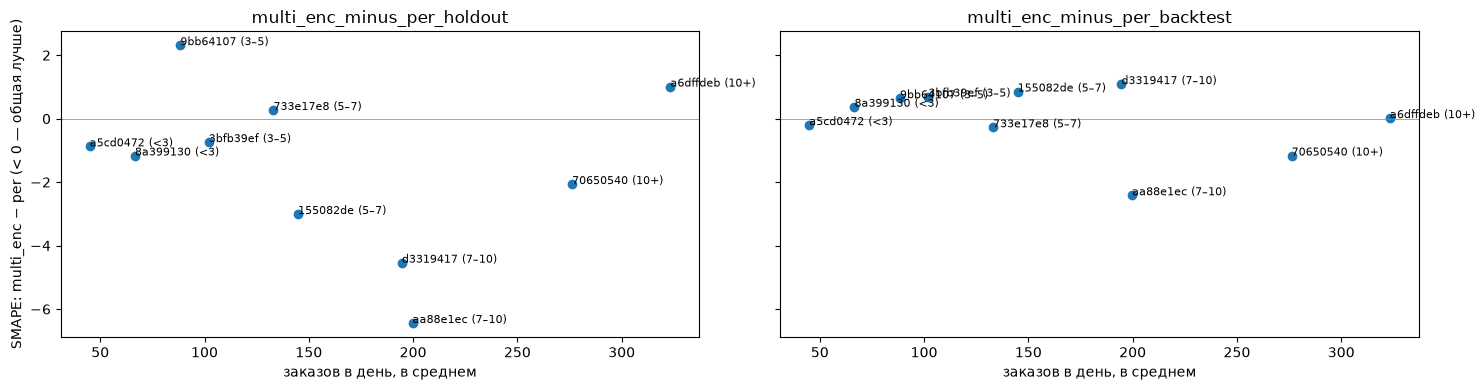

In [58]:
# Есть ли связь с размером юнита: выигрыш общей модели против среднего числа заказов в день
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for ax, column in zip(axes, ["multi_enc_minus_per_holdout", "multi_enc_minus_per_backtest"]):
    ax.scatter(smape_by_unit["mean_orders"], smape_by_unit[column])
    for segment, row in smape_by_unit.iterrows():
        ax.annotate(f"{segment} ({row['unit_size']})", (row["mean_orders"], row[column]), fontsize=8)
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.set_title(column)
    ax.set_xlabel("заказов в день, в среднем")
axes[0].set_ylabel("SMAPE: multi_enc − per (< 0 — общая лучше)")
plt.tight_layout()

print("корреляция выигрыша с размером юнита:")
smape_by_unit[["multi_enc_minus_per_holdout", "multi_enc_minus_per_backtest"]].corrwith(smape_by_unit["mean_orders"]).round(2)

#### Выводы

> Смотрим на **backtest** (среднее по 5 фолдам и 5 сидам) — он устойчивый. Holdout по одному юниту — одно окно и один сид, он сильно шумит: SMAPE одного юнита на holdout может поменяться на 1–2 от перезапуска.

| юнит | размер | заказов в день | `per_segment` | `multi_segment_enc` | общая − отдельные |
|---|---|---|---|---|---|
| `a6dffdeb` | 10+ | ~323 | ~7.8 | ~8.2 | +0.4 |
| `70650540` | 10+ | ~276 | ~12.5 | ~11.5 | **−1.1** |
| `aa88e1ec` | 7–10 | ~200 | ~14.5 | ~11.9 | **−2.6** |
| `d3319417` | 7–10 | ~195 | ~13.7 | ~14.8 | +1.1 |
| `155082de` | 5–7 | ~145 | ~15.3 | ~16.0 | +0.7 |
| `733e17e8` | 5–7 | ~133 | ~12.1 | ~11.3 | −0.8 |
| `3bfb39ef` | 3–5 | ~102 | ~13.1 | ~14.1 | +1.0 |
| `9bb64107` | 3–5 | ~88 | ~12.3 | ~13.0 | +0.7 |
| `8a399130` | <3 | ~67 | ~16.8 | ~17.5 | +0.7 |
| `a5cd0472` | <3 | ~45 | ~21.0 | ~20.8 | −0.2 |

**1. Общая модель — не «лучше для всех», а «кому как».** Она выиграла у отдельных моделей на 3 юнитах из 10 (плюс одна ничья) и проиграла на 6. В среднем — ничья (шаг Б.2), но за ней два заметных выигрыша и много мелких проигрышей.

**2. Где общая модель помогает — там, где отдельная модель слабая.** Два устойчивых выигрыша:
- `aa88e1ec`: отдельная модель ~14.5 во всех окнах — одна из худших среди крупных юнитов. Своих данных ей не хватает, общая модель подтягивает к «типичной неделе» и даёт ~11.9;
- `70650540`: ~12.5 → ~11.5 (тот самый юнит, которому в шаге 4.2 помогала длинная история — ему тоже не хватало данных).

Где у юнита свой узор хорошо выучивается и отдельно (`a6dffdeb` ~7.8, `9bb64107` ~12.3), общая модель слегка размывает его чужими юнитами — проигрыш 0.4–1.

**3. Связи с размером юнита почти нет.** Корреляция выигрыша с числом заказов в день — около −0.3: у крупных юнитов чуть чаще выигрыш, но в каждой размерной группе есть и выигрыш, и проигрыш (`70650540` и `a6dffdeb` — оба 10+, а эффект противоположный). Решает не размер, а то, насколько хорошо модель справляется с юнитом в одиночку.

**4. Holdout по юнитам обманывает ещё сильнее, чем macro.** `d3319417`: на holdout общая модель лучше почти на 5, на backtest — хуже на ~1. На одном окне в 14 дней по одному юниту решать нельзя.

**5. Мелкие юниты (<3) — худшие у всех вариантов** (17–21 на backtest). При 45–67 заказах в день случайные колебания сравнимы с уровнем, и процентная ошибка высокая у любой модели — это свойство юнитов, а не CatBoost.

**Практический вывод:** выбирать `PerSegment` / `MultiSegment` можно по юниту — общую модель туда, где отдельная проваливается. Но выигрыш на 2 юнитах из 10 не меняет общей картины: на этих данных CatBoost проигрывает простым моделям (шаг Б.2).

### Шаг Б.4. Логирование в MLflow

Залогируй каждый вариант отдельным запуском через `log_to_mlflow(...)`:
- имя запуска: `CatBoost_<вариант>_ch08_all_10_day`, например `CatBoost_per_segment_ch08_all_10_day`, `CatBoost_multi_segment_enc_ch08_all_10_day`;
- теги: `{"chapter": "ch08", "units_scope": "all_10", "granularity": "day", "model_family": "catboost", "approach": "one_config", "impl": "catboost"}` + теги варианта (`"segment_mode"`: `per_segment` / `multi_segment`, `"features"`: имя набора признаков);
- параметры: параметры модели, список лагов и прочих трансформов, `horizon`, `backtest_n_folds`, `backtest_mode`.

In [59]:
# Средние по 5 сидам (шаги Б.1 и Б.2) — отдельными метриками: одиночный запуск с RANDOM_SEED шумит на ~0.1–0.5
holdout_seed_mean = pd.DataFrame(seed_bonus_rows).groupby("variant")["smape_macro"].mean()
backtest_seed_mean = seed_backtest_df.groupby(["variant", "seed"])["smape_backtest"].mean().groupby("variant").mean()
for name, run in bonus_runs.items():
    run["agg"]["smape_macro_seed_mean"] = holdout_seed_mean[name]
    run["agg"]["smape_backtest_macro_seed_mean"] = backtest_seed_mean[name]

# Что уйдёт в MLflow — проверяем до логирования
pd.DataFrame({name: run["agg"] for name, run in bonus_runs.items()}).T.round(2)

,smape_macro,mape_macro,mae_macro,wape_pooled,bias_pooled,fit_sec,smape_backtest_macro,smape_macro_seed_mean,smape_backtest_macro_seed_mean
per_segment,13.64,17.69,18.49,11.95,1.06,1.42,13.87,13.71,13.94
multi_segment,12.44,16.03,16.48,10.65,-1.27,0.38,14.23,12.28,14.17
multi_segment_enc,12.11,15.64,15.91,10.28,-0.97,0.60,13.87,12.34,13.90


In [60]:
# Каждый вариант — отдельный запуск. Как найти их в MLflow UI:
#   Имя запуска: <run_label>_ch08_all_10_day, например CatBoost_multi_segment_enc_ch08_all_10_day
#   Теги: chapter / units_scope / granularity / approach — как у прошлых запусков; model_family = catboost, impl = catboost,
#         теги варианта — segment_mode (per_segment / multi_segment) и features. Фильтр в UI: tags.chapter = "ch08"
#   Метрики: holdout — как у прошлых запусков; smape_backtest_macro и smape_backtest/<segment> — как в ch07;
#            новые smape_macro_seed_mean и smape_backtest_macro_seed_mean — средние по 5 сидам
for name, run in bonus_runs.items():
    spec = run["spec"]
    log_to_mlflow(
        model_name=spec["run_label"],
        model_params={
            **{key: str(value) for key, value in spec["params"].items()},
            "horizon": HORIZON,
            "backtest_n_folds": BACKTEST_N_FOLDS,
            "backtest_mode": BACKTEST_MODE,
            "n_seeds_for_seed_mean": len(SEEDS),
        },
        metrics=run["agg"],
        metrics_per_segment=run["per_segment"],
        segment_table=run["result"],
        tags={
            "chapter": "ch08",
            "units_scope": "all_10",
            "granularity": "day",
            "model_family": "catboost",
            "approach": "one_config",
            "impl": "catboost",
            **spec["tags"],
        },
        run_name_suffix="ch08_all_10_day",
    )

#### Выводы

После запуска в MLflow появятся 3 запуска с тегом `chapter = ch08`:
- `CatBoost_per_segment_ch08_all_10_day` — `segment_mode = per_segment`;
- `CatBoost_multi_segment_ch08_all_10_day` — `segment_mode = multi_segment`;
- `CatBoost_multi_segment_enc_ch08_all_10_day` — `segment_mode = multi_segment`, `features = lags_weekly+segment_code`.

У всех — `model_family = catboost`, `impl = catboost`, `approach = one_config`, как у прошлых глав.

**Метрики:**
- holdout с теми же именами, что у прошлых глав: `smape_macro`, `mape_macro`, `mae_macro`, `wape_pooled`, `bias_pooled`, `fit_sec` и по юнитам `smape/<segment>`, `wape/<segment>`, …;
- backtest, как в ch07: `smape_backtest_macro` и `smape_backtest/<segment>`;
- **новые:** `smape_macro_seed_mean` и `smape_backtest_macro_seed_mean` — средние по 5 сидам. Одиночный запуск с `RANDOM_SEED` от перезапуска к перезапуску плавает на 0.1–0.5 SMAPE, а этого достаточно, чтобы поменять ранги CatBoost относительно других моделей. **Для сравнения CatBoost с прошлыми моделями берём `*_seed_mean`.** У Prophet и ETS случайности нет, им такая метрика не нужна.

**Параметры:** класс модели, набор признаков и список лагов, `segment_encoder`, `random_seed`, `horizon`, `backtest_n_folds`, `backtest_mode`, `n_seeds_for_seed_mean`.

**Артефакт:** `metrics_by_segment.json` — таблица по юнитам (описание юнита + все метрики holdout и backtest).

Если ячейку логирования запустить повторно, в MLflow появятся дубликаты запусков с теми же именами. В шаге Б.5 берём самый свежий запуск (`drop_duplicates`), как в тетради про `ProphetModel`.

#### Итого. Выводы

**Что проверяли:** главное преимущество бустинга, которого нет у прошлых моделей, — **одна модель на все юниты** (`MultiSegment`) вместо отдельной модели на каждый (`PerSegment`). `HoltWintersModel`, `ProphetModel` и `SARIMAXModel` всегда учатся на каждом юните изолированно — «среднее по юнитам» у них только в метрике, а не в обучении.

| модель | holdout SMAPE (последние 14 дней) | backtest SMAPE (5 окон × 14 дней) |
|---|---|---|
| `Prophet_flat` | 12.46 | **12.61** |
| `Prophet_mult` | 11.92 | 12.75 |
| `HoltWinters_add_add` | **11.31** | 13.18 |
| CatBoost `per_segment` | ~13.7 | ~13.9 |
| CatBoost `multi_segment_enc` | ~12.3 | ~13.8 |

*SMAPE macro — среднее по 10 юнитам. Для CatBoost ещё и среднее по 5 запускам с разными `random_seed`: его результат немного зависит от случайности, а у Prophet и HoltWinters случайности нет.*

**Выводы:**
- **На одном окне общая модель выглядит заметно лучше** — **но в backtest преимущество исчезает.** Общая модель выигрывает только в поздних окнах, где истории больше; holdout — как раз самое позднее.
- **Общая модель помогает не всем, а слабым:** юнитам, где отдельная модель проваливается (`aa88e1ec`: 14.5 → 11.9), — и слегка вредит тем, кто хорошо выучивается в одиночку. Итог по 10 юнитам — ничья.
- **По backtest CatBoost хуже всех прошлых моделей** (~13.8 против 12.6–13.2). На holdout он был в середине таблицы — одно окно в 14 дней снова поменяло вывод о модели.
- **Почему:** 4.5 месяца истории, в рядах только уровень и недельный узор, признаки — лишь прошлые значения самого ряда. Сильные стороны бустинга — много данных, много признаков, нелинейные зависимости — здесь не задействованы.

**Итог:** на наших данных CatBoost простым моделям проигрывает. Шанс у него появится с длинной историей и внешними признаками — праздниками, погодой, акциями.